# Bước C - Huấn luyện một cấu hình của mô hình chung Sequential Forecast (lõi LSTM, GRU, Transformer, S4D hoặc Mamba)
# trên Extended LamaH-CE, 30 epoch, Kaggle T4. Cùng một khuôn cho tinh chỉnh C1 (1 hạt giống, chỉ validation) và chạy
# chính thức C2 (3 hạt giống, thêm chấm test mọi epoch). C1 loại sớm hai vòng (02_Pipeline.md Mục 5.2): notebook phiên 1
# dừng ở epoch 15 (lịch cosine vẫn T_max 30), notebook _Cont của cấu hình được giữ chạy tiếp epoch 16-30.
# Bài: Konold và cs., HESS 30:5067-5096 (2026). Dữ liệu Zenodo 17119635 (CC BY-NC 4.0), config tác giả Zenodo 17292895
#      - đã lưu thành Kaggle Dataset "lamah-ce-ext".
# Kế hoạch: Document/01_Plan/02_Pipeline.md Mục 5.1 (giao thức 30 epoch), 5.2 (lưới C1, siêu tham số ngoài lưới),
# 7 (dòng C1, C2), 9.1 (cài thư viện theo commit). Thời gian từng cấu hình:
# Workspace/04_Setup/05_0_C_Configs_Check/05_0_C_Configs_Check.md.
# Tệp sinh từ Tools/C_Notebook_Template.py bằng Tools/C_Notebooks_Build.py: các tệp chỉ khác khối CẤU HÌNH ở Phần 1.
# Tên notebook Kaggle trùng tên tệp. Notebook phiên 2 cùng tên thêm đuôi "_Cont" (cùng mã, khối CẤU HÌNH chỉ khác tên
# notebook; thêm Input = Output notebook phiên 1; tài khoản khác chạy được khi notebook phiên 1 đã chia sẻ) chạy tiếp:
# C1 - vòng 2 của cấu hình được giữ ở 11_C1_LamaHCEExt_Compare; C2 - cấu hình không xong trong một phiên (Phần 5 dừng
# trước giới hạn 12 giờ).
# Cài đặt: Accelerator = GPU T4 x2 (dùng GPU 0), Internet = On, Persistence = Files only,
# Environment = Pin to original environment, Add Input => lamah-ce-ext, Output notebook 01_0_MambaSSM_Build
# (Version 1, wheel mamba-ssm, causal-conv1d) và Output notebook 08_B3_LamaHCEExt_Train_P10S12_Seed111 (Version 1, B*:
# config.yml đối chiếu ở Phần 4). Dán nguyên tệp rồi Save & Run All, không sửa dòng nào.
#
# MỤC LỤC
#   Phần 1 - Cấu hình chạy, cài fork nhánh research và mamba-ssm, kiểm môi trường
#   Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
#   Phần 3 - Dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd
#   Phần 4 - Config B* cho cấu hình của khối CẤU HÌNH, khớp tham số
#   Phần 5 - Huấn luyện (C1 vòng 1 tới epoch 15, còn lại tới 30; validation mỗi epoch), dừng gọn trước giới hạn
#            phiên; phiên 2 chạy tiếp
#   Phần 6 - Kiểm best_model.pt, validation theo epoch; C2: chấm test mọi epoch và best_model.pt
#   Phần 7 - Hình đường học theo epoch và loss theo bước
#   Phần 8 - Tóm tắt, môi trường, danh mục tệp, dọn thư mục dữ liệu tạm, trạng thái run

Mục,Giá trị
notebook,10_C1_Tune_lstm_L2_x3_lr1e-3_Cont
bước,C1
lõi,lstm
độ sâu,2
mức dung lượng,x3
learning rate,0.001
hạt giống,111
tên run,C1_lstm_L2_x3_lr1e-3_seed111
phiên,2
huấn luyện tới epoch,30 / 30


mamba-ssm đã cài từ /kaggle/input/notebooks/hunhngcthng/01-0-mambassm-build/wheels (dựng 2026-10-23T15:42:20+00:00, torch 2.11.0+cu128, sm_75); chạy thử xuôi + ngược đạt


Thư viện,Phiên bản,pip đổi?
neuralhydrology,1.12.0 (commit db6dc1f),
mamba_ssm,2.3.2.post1,
causal_conv1d,1.6.2.post1,
numpy,2.1.3,
pandas,2.3.3,
xarray,2025.12.0,
torch,2.11.0+cu128,
scipy,1.16.3,
numba,0.61.2,
ruamel.yaml,0.19.1,


Mục,Giá trị
Python,3.13.15
torch / CUDA của torch,2.11.0+cu128 / 12.8
cuDNN,91900
Số GPU,2
GPU,"0: Tesla T4 (cc 7.5, 14.6 GB); 1: Tesla T4 (cc 7.5, 14.6 GB)"
Số CPU,4
RAM tổng / còn trống (GB),31.3 / 28.9
Đĩa trống ở WORK_DIR (GB),19.5
Ngày dựng ảnh Kaggle,20261022-041805
Wheel mamba-ssm,/kaggle/input/notebooks/hunhngcthng/01-0-mambassm-build/wheels


Điều kiện,Đạt
Cài đúng commit db6dc1f,ĐẠT
Nạp neuralhydrology từ site-packages,ĐẠT
pip không đổi thư viện có sẵn,ĐẠT
Có GPU T4 (dùng GPU 0),ĐẠT
Có tensorboard,ĐẠT
Nạp nh_run,ĐẠT
Nạp tester,ĐẠT
Nạp gpu_loader,ĐẠT
Nạp sequential_forecast,ĐẠT
Nạp sf_cores,ĐẠT


neuralhydrology nạp từ: /usr/local/lib/python3.13/dist-packages/neuralhydrology
=> Đạt. Chạy Phần 2.


... (20 outputs left out)

Thư mục run: /kaggle/working/c_runs/C1_lstm_L2_x3_lr1e-3_seed111_0311_024505
Trạng thái huấn luyện: xong 30 epoch
=> Đạt. Chạy Phần 6.
C1: không chấm test (Pipeline Mục 7) - chỉ validation.


epoch,loss huấn luyện,loss validation,NSE trung vị validation (tệp),KGE trung vị validation (tệp),ghi chú
1,0.01889,0.01189,0.6643,0.6808,
2,0.01268,0.01068,0.6988,0.691,
3,0.01131,0.01019,0.718,0.7248,
4,0.01048,0.00964,0.7293,0.7569,
5,0.01,0.00974,0.7234,0.6903,
6,0.00943,0.00921,0.7518,0.7634,
7,0.00922,0.00908,0.752,0.7814,
8,0.00888,0.00877,0.7555,0.7865,
9,0.00868,0.00923,0.7398,0.733,
10,0.00847,0.00882,0.7534,0.7988,


mục,giá trị,cần,đạt
best_model.pt trùng tensor với đúng 1 epoch,[16],1 epoch,ĐẠT
Epoch best_model.pt = epoch Phần 5 ghi sau cùng = epoch NSE validation cao nhất (tệp),16 / 16 / 16,bằng nhau,ĐẠT
"NSE, KGE validation tệp khớp log (từng epoch)",30 / 30,sai lệch <= 0.0001,ĐẠT
Validation đủ 451 lưu vực mỗi epoch,[451],[451],ĐẠT


=> Đạt. Chạy Phần 7.


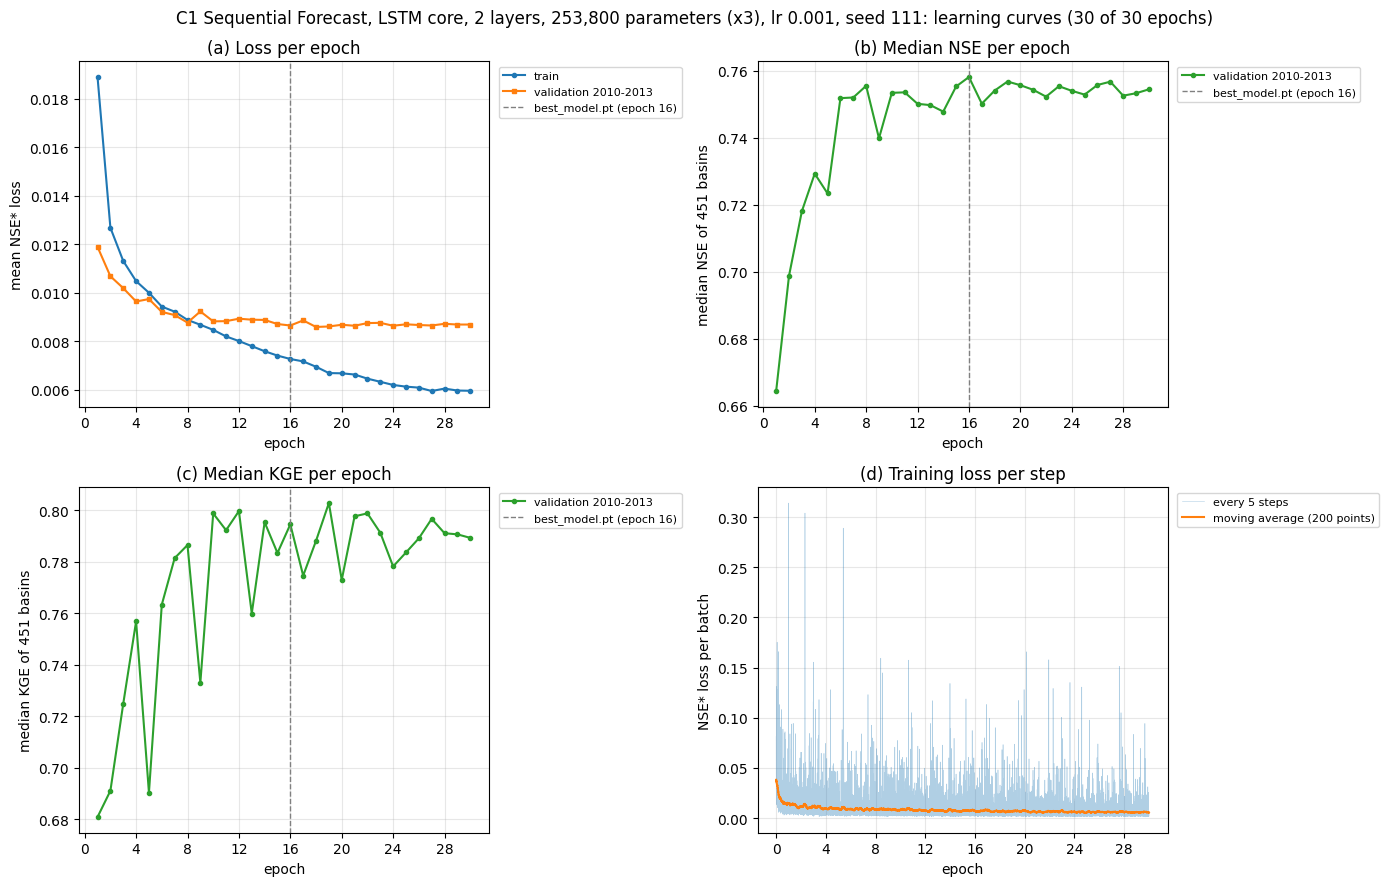

Hình: đường học của lõi LSTM 2 lớp, 253.800 tham số, learning rate 0,001, hạt giống 111, 30 / 30 epoch. (a) loss NSE* trung bình mỗi epoch của kỳ huấn luyện và kỳ validation; loss huấn luyện giảm trong khi loss validation tăng là dấu hiệu quá khớp. (b), (c) NSE và KGE trung vị 451 lưu vực của kỳ validation (dùng để chọn mô hình); vạch xám là epoch lưu thành best_model.pt (epoch 16: NSE validation 0,758). (d) loss của từng lô 256 mẫu, ghi mỗi 5 bước (26070 điểm), đường cam là trung bình trượt 200 điểm; trục ngang đổi ra epoch (4345 bước/epoch).
Đã lưu /kaggle/working/c_output/Figures/C1_Curve_C1_lstm_L2_x3_lr1e-3_seed111.png
=> Đạt. Chạy Phần 8.


tệp,KB,sha256
c_runs/C1_lstm_L2_x3_lr1e-3_seed111_0311_024505/config.yml,3.7,de1021edb412...
c_runs/C1_lstm_L2_x3_lr1e-3_seed111_0311_024505/train_data/train_data_scaler.yml,8.6,baae107de375...
c_runs/C1_lstm_L2_x3_lr1e-3_seed111_0311_024505/best_model.pt,1025,fa8d01c746fb...
c_runs/C1_lstm_L2_x3_lr1e-3_seed111_0311_024505/output.log,31.9,9e304658d1f5...
c_runs/C1_lstm_L2_x3_lr1e-3_seed111_0311_024505/model_epoch030.pt,1025,e702f91d1bc2...
c_runs/C1_lstm_L2_x3_lr1e-3_seed111_0311_024505/optimizer_state_epoch030.pt,2054,2e85355ae9eb...
c_runs/C1_lstm_L2_x3_lr1e-3_seed111_0311_024505/training_state_epoch030.pt,15.2,4ce4425fae4a...
c_runs/C1_lstm_L2_x3_lr1e-3_seed111_0311_024505/events.out.tfevents.1793673987.4fb907ea9fc6.157.0,1387,c1ec02eccec6...
c_runs/C1_lstm_L2_x3_lr1e-3_seed111_0311_024505/events.out.tfevents.1794033229.b31ba1c7cb26.157.0,1393,72080cfa5767...


thư mục,GB
c_configs,0
c_output,0.002
c_runs,0.583


mục,giá trị,cần,đạt
Đủ tệp chính trong thư mục run,9 / 9,đủ,ĐẠT
Có tệp sự kiện tensorboard,2,>= 1,ĐẠT
Commit thư viện đúng db6dc1f,db6dc1f,db6dc1f,ĐẠT
Đã xóa thư mục dữ liệu tạm,True,True,ĐẠT
Tổng Output,0.58 GB,<= 20 GB,ĐẠT


mục,giá trị
Trạng thái,xong
Epoch đã huấn luyện,30 / 30
Epoch đã chấm test,- (C1 không chấm test)
best_model.pt,"epoch 16, NSE trung vị validation 0.7581"
Thời gian phiên,7.40 giờ
Việc tiếp,không


=> Đạt. Xong notebook.


In [1]:
# %% Phần 1 - Cấu hình chạy, cài fork nhánh research và mamba-ssm, kiểm môi trường
# Khối CẤU HÌNH là chỗ duy nhất khác giữa các tệp (Tools/C_Notebooks_Build.py ghi lại khối này), kiểm giá trị hợp lệ theo
# lưới C1 (02_Pipeline.md Mục 5.2). Ghi mốc giờ bắt đầu phiên cho giới hạn huấn luyện ở Phần 5. Cài fork theo mã commit
# (Pipeline Mục 9.1), cài wheel mamba-ssm theo cell Phần 9 của 01_0_MambaSSM_Build. In 4 bảng (cấu hình, thư viện,
# môi trường, điều kiện); chưa đạt => raise để Save & Run All dừng ngay, không tốn giờ GPU.
import time

SESSION_T0 = time.time()                 # mốc đầu phiên: Phần 5 trừ thời gian đã dùng khỏi giới hạn huấn luyện

# ---- CẤU HÌNH (Tools/C_Notebooks_Build.py ghi lại khối này) ----
NOTEBOOK = "10_C1_Tune_lstm_L2_x3_lr1e-3_Cont"
STEP = "C1"                              # C1: tinh chỉnh, chỉ validation; C2: chạy chính thức, thêm chấm test mọi epoch
CORE = "lstm"                            # lstm, gru, transformer, s4d, mamba
DEPTH = 2                                # số lớp (LSTM, GRU, Transformer 1/2) hoặc số khối (S4D, Mamba 2/4)
LEVEL = 3                                # mức dung lượng: 1 = cùng tham số với LSTM của B*, 3 = gấp khoảng 3 lần
LR = 1e-3                                # learning rate: 1e-3 hoặc 5e-4
RUN_SEED = 111                           # C1 chỉ hạt giống 111; C2 111, 222, 333
# ---- HẾT CẤU HÌNH ----

import hashlib
import importlib
import importlib.metadata as md
import json
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

NH_REPO = "https://github.com/Ticasslo/neuralhydrology.git"
NH_COMMIT = "db6dc1ffcd8c14994cd80be3ed8ff417002c01a1"   # tag freeze-C: 5 lõi (fed53dc) + chạy tiếp (5844037) + B2/B3
CHECK_LIBS = ["numpy", "pandas", "xarray", "torch", "scipy", "numba", "ruamel.yaml", "matplotlib", "tensorboard", "tqdm"]
NH_MODULES = ["neuralhydrology.nh_run", "neuralhydrology.evaluation.tester", "neuralhydrology.datautils.gpu_loader",
              "neuralhydrology.modelzoo.sequential_forecast", "neuralhydrology.modelzoo.sf_cores",
              "neuralhydrology.datautils.source_groups"]
TORCH_B0 = "2.11.0+cu128"                # torch của B0, B1a, B1b, 04_0 (ảnh Kaggle 10/2026); khác thì chỉ cảnh báo

IS_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("c_work")
OUT_DIR = WORK_DIR / "c_output"          # bảng, hình, tóm tắt, môi trường, log tiến trình huấn luyện
WHEEL_ROOTS = [Path("/kaggle/input"), WORK_DIR / "wheels"]
SESSION_LIMIT_H = 11.0                   # giới hạn phiên Kaggle 12 giờ (kaggle.com/docs/notebooks), chừa 1 giờ lưu Output
EPOCHS_FULL = 30                         # giao thức 30 epoch, lịch cosine T_max 30 (Pipeline Mục 5.1)
C1_CUT = 15                              # C1 vòng 1 dừng ở epoch này (Pipeline Mục 5.2: xếp hạng ở epoch 15 trùng epoch 30
                                         # trên 18 lần chạy B0-B3, Spearman 0,99)
CORE_DEPTHS = {"lstm": (1, 2), "gru": (1, 2), "transformer": (1, 2), "s4d": (2, 4), "mamba": (2, 4)}
WORK_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Kiểm khối CẤU HÌNH theo lưới C1 (Pipeline Mục 5.2) và tên notebook khớp cấu hình
BASE_NOTEBOOK = NOTEBOOK.removesuffix("_Cont")         # notebook phiên 2 = tên phiên 1 + "_Cont"
SESSION = 2 if NOTEBOOK.endswith("_Cont") else 1
conf_name = f"{CORE}_L{DEPTH}_x{LEVEL}"
lr_tag = {1e-3: "lr1e-3", 5e-4: "lr5e-4"}.get(LR)
conf_errors = [msg for ok, msg in [
    (STEP in ("C1", "C2"), f"STEP {STEP} phải là C1 hoặc C2"),
    (DEPTH in CORE_DEPTHS.get(CORE, ()), f"lõi {CORE} độ sâu {DEPTH} không có trong lưới {CORE_DEPTHS}"),
    (LEVEL in (1, 3), f"LEVEL {LEVEL} phải là 1 hoặc 3"),
    (lr_tag is not None, f"LR {LR} phải là 1e-3 hoặc 5e-4"),
    (RUN_SEED in ((111,) if STEP == "C1" else (111, 222, 333)), f"hạt giống {RUN_SEED} không dùng ở {STEP}"),
    (f"_{STEP}_" in BASE_NOTEBOOK and f"_{conf_name}_" in BASE_NOTEBOOK and str(lr_tag) in BASE_NOTEBOOK
     and (STEP == "C1" or BASE_NOTEBOOK.endswith(f"_Seed{RUN_SEED}")), f"tên notebook {NOTEBOOK} không khớp cấu hình"),
] if not ok]
if conf_errors:
    raise ValueError("Khối CẤU HÌNH sai: " + "; ".join(conf_errors))
EXP_NAME = f"{STEP}_{conf_name}_{lr_tag}_seed{RUN_SEED}"   # tên run (experiment_name), thư mục run bắt đầu bằng tên này
# Khóa epochs ghi trong config.yml của run (C1 dừng ở vòng 1) và epoch cuối phiên này huấn luyện tới (C1 _Cont chạy tiếp
# tới EPOCHS_FULL bằng config phụ ở Phần 5)
CFG_EPOCHS = C1_CUT if STEP == "C1" else EPOCHS_FULL
N_EPOCHS = C1_CUT if STEP == "C1" and SESSION == 1 else EPOCHS_FULL


def installed_versions(libs):
    # Phiên bản đang cài trên đĩa (không phụ thuộc thứ đã nạp vào bộ nhớ).
    out = {}
    for lib in libs:
        try:
            out[lib] = md.version(lib)
        except md.PackageNotFoundError:
            out[lib] = None
    return out


def mem_gb(key):
    # Đọc /proc/meminfo (kB) => GB.
    for line in Path("/proc/meminfo").read_text().splitlines():
        if line.startswith(key + ":"):
            return int(line.split()[1]) / 1024 ** 2
    return None


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    # số thực in 4 chữ số có nghĩa (mặc định Styler in 6 chữ số thập phân)
    display(df.style.hide(axis="index").format({c: "{:.4g}" for c in df.select_dtypes("float").columns}))


def run(cmd, cwd=None):
    subprocess.run(cmd, cwd=cwd, check=True)


def installed_commit(dist):
    # Commit pip ghi lúc cài từ git (direct_url.json của bản cài), để chắc đúng phiên bản thư viện.
    text = md.distribution(dist).read_text("direct_url.json")
    return json.loads(text)["vcs_info"]["commit_id"] if text else None


def mamba_install():
    # Chép từ 01_0_MambaSSM_Build Phần 9: tìm build_info.json, kiểm Python/torch/CUDA khớp lúc dựng, sha256, cài --no-deps,
    # chạy thử một khối Mamba xuôi + ngược.
    import torch
    infos = [p for root in WHEEL_ROOTS if root.exists() for p in root.rglob("build_info.json")]
    if not infos:
        raise FileNotFoundError("Không thấy build_info.json: gắn Output của notebook 01_0_MambaSSM_Build làm Input")
    if len(infos) > 1:
        print("Thấy nhiều build_info.json, dùng tệp đầu tiên:", *infos, sep="\n  ")
    info_path = infos[0]
    info = json.loads(info_path.read_text())
    now = {"python": platform.python_version(), "torch": torch.__version__, "torch_cuda": torch.version.cuda}
    diff = {k: (info[k], v) for k, v in now.items() if info[k] != v}
    if diff:
        raise RuntimeError(f"Môi trường khác lúc dựng wheel (lúc dựng, bây giờ): {diff}. Phải dựng lại ở 01_0_MambaSSM_Build")
    gpu_cc = torch.cuda.get_device_capability(0) if torch.cuda.is_available() else None
    if gpu_cc != (7, 5):
        raise RuntimeError(f"Wheel chỉ có mã cho {info['arch']} (T4), GPU hiện tại: {gpu_cc}")
    wheels = []
    for name, digest in info["wheels"].items():
        whl = info_path.parent / name
        if hashlib.sha256(whl.read_bytes()).hexdigest() != digest:
            raise RuntimeError(f"sha256 của {name} không khớp build_info.json")
        wheels.append(str(whl))
    torch_dist = md.version("torch")  # bản đã cài trên đĩa (torch.__version__ không đổi khi pip cài lại)
    run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", *wheels])
    if md.version("torch") != torch_dist:
        raise RuntimeError("torch bị đổi sau khi cài wheel, khởi động lại phiên và kiểm lại lệnh cài")
    from mamba_ssm import Mamba
    m = Mamba(d_model=16).cuda()
    y = m(torch.randn(2, 8, 16, device="cuda", requires_grad=True))
    y.sum().backward()
    if not torch.isfinite(y).all():
        raise RuntimeError("Khối Mamba chạy thử ra NaN/inf")
    print(f"mamba-ssm đã cài từ {info_path.parent} (dựng {info['built_at']}, torch {info['torch']}, {info['arch']}); "
          f"chạy thử xuôi + ngược đạt")
    return info, info_path


show("Cấu hình chạy", pd.DataFrame({"Mục": ["notebook", "bước", "lõi", "độ sâu", "mức dung lượng", "learning rate",
                                             "hạt giống", "tên run", "phiên", "huấn luyện tới epoch", "giới hạn phiên (giờ)"],
                                     "Giá trị": [NOTEBOOK, STEP, CORE, DEPTH, f"x{LEVEL}", LR, RUN_SEED, EXP_NAME,
                                                 SESSION, f"{N_EPOCHS} / {EPOCHS_FULL}", SESSION_LIMIT_H]}).astype(str))

# Cài fork theo commit (không editable: thư viện nằm trong site-packages như các notebook trước)
before = installed_versions(CHECK_LIBS)
run([sys.executable, "-m", "pip", "install", "-q", f"git+{NH_REPO}@{NH_COMMIT}"])
after = installed_versions(CHECK_LIBS)
importlib.invalidate_caches()  # để tiến trình đang chạy thấy gói vừa cài
changed = [k for k in CHECK_LIBS if before[k] != after[k]]
NH_INSTALLED_COMMIT = installed_commit("neuralhydrology")

MAMBA_BUILD_INFO, MAMBA_INFO_PATH = mamba_install()
mamba_versions = installed_versions(["mamba_ssm", "causal_conv1d"])

show("Thư viện (sau khi cài fork và mamba-ssm)", pd.DataFrame({
    "Thư viện": ["neuralhydrology", "mamba_ssm", "causal_conv1d"] + CHECK_LIBS,
    "Phiên bản": [f"{md.version('neuralhydrology')} (commit {(NH_INSTALLED_COMMIT or 'không rõ')[:7]})",
                  mamba_versions["mamba_ssm"] or "THIẾU", mamba_versions["causal_conv1d"] or "THIẾU"]
                 + [after[k] or "THIẾU" for k in CHECK_LIBS],
    "pip đổi?": ["", "", ""] + [f"từ {before[k]}" if before[k] != after[k] else "" for k in CHECK_LIBS]}))

import torch  # nạp sau khi cài để in đúng thiết bị

n_gpu = torch.cuda.device_count()
gpus = [f"{i}: {torch.cuda.get_device_name(i)} (cc {'.'.join(map(str, torch.cuda.get_device_capability(i)))}, "
        f"{torch.cuda.get_device_properties(i).total_memory / 1024 ** 3:.1f} GB)" for i in range(n_gpu)]
build_date = Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có"
ENV = {
    "Python": platform.python_version(),
    "torch / CUDA của torch": f"{torch.__version__} / {torch.version.cuda}",
    "cuDNN": torch.backends.cudnn.version(),
    "Số GPU": n_gpu,
    "GPU": "; ".join(gpus) or "không có GPU",
    "Số CPU": os.cpu_count(),
    "RAM tổng / còn trống (GB)": f"{mem_gb('MemTotal'):.1f} / {mem_gb('MemAvailable'):.1f}",
    "Đĩa trống ở WORK_DIR (GB)": f"{shutil.disk_usage(WORK_DIR).free / 1024 ** 3:.1f}",
    "Ngày dựng ảnh Kaggle": build_date,
    "Wheel mamba-ssm": str(MAMBA_INFO_PATH.parent),
}
show("Môi trường", pd.DataFrame({"Mục": list(ENV), "Giá trị": [str(v) for v in ENV.values()]}))

# Thử nạp các module sẽ dùng; sf_cores phải thấy mamba_ssm (MambaSSM khác None) thì lõi mamba mới dựng được
import_ok = {}
for mod in NH_MODULES:
    try:
        importlib.import_module(mod)
        import_ok[mod] = "ĐẠT"
    except Exception as e:  # in lỗi thật để biết thiếu gì
        import_ok[mod] = f"LỖI: {type(e).__name__}: {e}"

from neuralhydrology.modelzoo import sf_cores
from neuralhydrology.utils.config import Config

nh_path = Path(importlib.import_module("neuralhydrology").__file__).resolve()
checks = {
    f"Cài đúng commit {NH_COMMIT[:7]}": NH_INSTALLED_COMMIT == NH_COMMIT,
    "Nạp neuralhydrology từ site-packages": "site-packages" in str(nh_path) or "dist-packages" in str(nh_path),
    "pip không đổi thư viện có sẵn": not changed,
    "Có GPU T4 (dùng GPU 0)": n_gpu >= 1 and "T4" in gpus[0],
    "Có tensorboard": after["tensorboard"] is not None,
    **{f"Nạp {m.split('.')[-1]}": v == "ĐẠT" for m, v in import_ok.items()},
    "sf_cores thấy mamba_ssm": sf_cores.MambaSSM is not None,
    "Config có khóa sf_core, sf_dropout, sf_s4d_lr, data_on_gpu, max_training_hours, resume_training_state": all(
        isinstance(getattr(Config, k, None), property)
        for k in ["sf_core", "sf_dropout", "sf_s4d_lr", "data_on_gpu", "max_training_hours", "resume_training_state"]),
}
show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks.values()]}))
for mod, v in import_ok.items():
    if v != "ĐẠT":
        print(f"{mod}: {v}")
print(f"neuralhydrology nạp từ: {nh_path.parent}")

if torch.__version__ != TORCH_B0:
    print(f"Cảnh báo: torch {torch.__version__} khác bản của B0, B1a, B1b ({TORCH_B0}) - ảnh Kaggle đã đổi; ghi lại.")
if changed:
    print("Cảnh báo: pip đã đổi thư viện có sẵn:", ", ".join(f"{k} {before[k]} => {after[k]}" for k in changed))
if not all(v for k, v in checks.items() if k != "pip không đổi thư viện có sẵn"):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở bảng Điều kiện) - dừng notebook")
print("=> Đạt. Chạy Phần 2.")


# %% Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
# Chép nguyên 05_0_C_Configs_Check Phần 2 (= B1b Phần 2, đã chạy đạt ở 3 notebook B1b Version 1 và 05_0 Version 1;
# chỉ khác tên thư mục làm việc ở máy và cách show in số thực).
# Chỉ đọc, như B0 Phần 2: tìm dữ liệu và kết quả tác giả trong Input, đọc config.yml của run SeqLSTM có Q nhúng đơn giản,
# kiểm đúng run bằng các siêu tham số, rồi xếp mọi khóa config vào 3 nhóm: giữ nguyên / đổi ở Phần 4 / bỏ.
# Khác B0: hindcast_inputs và dynamic_inputs cùng đổi ở Phần 4 (qmean => qmean_mmd, qmax_mmd tại cùng vị trí). dynamic_inputs là
# danh sách cột bộ nạp đọc vào bộ nhớ (basedataset.py dòng 350-353, 575-586); hindcast_inputs, forecast_inputs chỉ lấy lại
# từ các cột đó (dòng 172-176), thư viện không tự dựng dynamic_inputs (config.py dòng 360-362 ở f229e02) => phải đổi cả hai danh sách.
# Kiểm dynamic_inputs của tác giả = hindcast_inputs + forecast_inputs. Tên cột mới phải nằm ngoài _VALID_TARGETS của
# bộ nạp (lamah.py dòng 18, 122-135): tên trong danh sách đó bị đọc lại từ D_gauges thay vì tệp khí tượng.
# Tự đủ: chạy lại được sau Restart mà không cần chạy lại Phần 1.
import os
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML, display
from ruamel.yaml import YAML

from neuralhydrology.datasetzoo.lamah import _VALID_TARGETS

IS_KAGGLE = Path("/kaggle/working").exists()
SEARCH_ROOT = Path(os.environ.get("LAMAH_ROOT", "/kaggle/input" if IS_KAGGLE else "."))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("c_work")
AUTHOR_RUN_REL = ("Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/"
                  "Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding")
N_BASINS = 451
Q_OLD = "qmean"                          # cột Q quá khứ của tác giả (m³/s)
Q_NEW = ["qmean_mmd", "qmax_mmd"]        # cột Q mm/ngày theo area_gov dựng ở Phần 3 (như B1a)
Q_USE = ["qmean_mmd", "qmax_mmd"]        # cột B1b, B* đưa vào config thay Q_OLD (qmax_mmd ngay sau qmean_mmd)
# Giá trị phải có trong config tác giả (như B0 Phần 2) - lệch là đọc nhầm run
EXPECTED = {"model": "sequential_forecast_lstm", "seed": 111, "hidden_size": 128, "batch_size": 256, "epochs": 30,
            "learning_rate": 0.001, "output_dropout": 0.3, "seq_length": 365, "forecast_seq_length": 1,
            "early_stopping_patience": 5, "early_stopping_min_delta": 0.005, "early_stopping_metric": "NSE",
            "loss": "NSE", "clip_gradient_norm": 1, "target_variables": ["qmax"]}
# Khóa đổi ở Phần 4: 12 khóa của B0 (đường dẫn, thiết bị, số tiến trình đọc, thanh tiến độ, hạt giống, tên run, giao thức
# 30 epoch, dữ liệu sẵn trên GPU) + 2 danh sách biến; khóa bỏ như B0
KEYS_CHANGE = ["data_dir", "run_dir", "train_basin_file", "validation_basin_file", "test_basin_file",
               "device", "num_workers", "verbose", "seed", "experiment_name", "early_stopping_patience", "data_on_gpu",
               "hindcast_inputs", "dynamic_inputs"]
KEYS_DROP = ["commit_hash", "package_version", "number_of_basins", "train_dir", "img_log_dir"]


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    # số thực in 4 chữ số có nghĩa (mặc định Styler in 6 chữ số thập phân)
    display(df.style.hide(axis="index").format({c: "{:.4g}" for c in df.select_dtypes("float").columns}))


def find_dir(root, name):
    # Thư mục duy nhất tên `name` dưới `root`; báo lỗi rõ nếu không có hoặc có nhiều.
    hits = sorted(p for p in root.rglob(name) if p.is_dir())
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 thư mục '{name}' dưới {root}, thấy {len(hits)}: {hits} - kiểm Input lamah-ce-ext")
    return hits[0]


def brief(value, width=90):
    # Rút gọn giá trị config để bảng dễ đọc (danh sách dài => số phần tử + vài phần tử đầu).
    if isinstance(value, list) and len(value) > 4:
        text = f"[{len(value)}] " + ", ".join(map(str, value[:3])) + ", ..."
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


# (1) Đường dẫn, danh sách lưu vực, tệp của run tác giả
LAMAH_DIR = find_dir(SEARCH_ROOT, "LamaH_extended")
EXP_DIR = find_dir(SEARCH_ROOT, "Experiments")
BASIN_FILE = EXP_DIR / "basins_filtered.txt"
basins = BASIN_FILE.read_text().split()
AUTHOR_RUN = EXP_DIR / AUTHOR_RUN_REL
AUTHOR_FILES = {"config": AUTHOR_RUN / "config.yml", "best_model.pt": AUTHOR_RUN / "best_model.pt",
                "scaler": AUTHOR_RUN / "train_data" / "train_data_scaler.yml",
                "test_metrics": AUTHOR_RUN / "test" / "best_model" / "test_metrics.csv"}
show("Đường dẫn và tệp", pd.DataFrame(
    [("Dữ liệu", str(LAMAH_DIR), ""), ("Kết quả tác giả", str(EXP_DIR), ""),
     ("Danh sách lưu vực", str(BASIN_FILE), f"{len(basins)} lưu vực, {len(set(basins))} mã khác nhau")]
    + [(f"Run tác giả: {k}", str(p.relative_to(EXP_DIR)), "có" if p.exists() else "THIẾU") for k, p in AUTHOR_FILES.items()],
    columns=["mục", "đường dẫn", "ghi chú"]))
if len(basins) != N_BASINS or len(set(basins)) != N_BASINS or not all(p.exists() for p in AUTHOR_FILES.values()):
    raise RuntimeError("Thiếu tệp của run tác giả hoặc danh sách lưu vực không đủ 451 mã khác nhau")

# (2) Config tác giả: kiểm đúng run, vị trí qmean, tên cột mới
AUTHOR_CFG = YAML(typ="safe").load(AUTHOR_FILES["config"].read_text(encoding="utf-8"))
exp_rows = [{"khóa": k, "mong đợi": brief(v), "trong config": brief(AUTHOR_CFG.get(k)),
             "khớp": "ĐẠT" if AUTHOR_CFG.get(k) == v else "KHÔNG"} for k, v in EXPECTED.items()]
groups = {"hindcast_inputs": AUTHOR_CFG["hindcast_inputs"], "forecast_inputs": AUTHOR_CFG["forecast_inputs"],
          "static_attributes": AUTHOR_CFG["static_attributes"]}
hind = groups["hindcast_inputs"]
dyn = AUTHOR_CFG["dynamic_inputs"]
dyn_ok = dyn == hind + groups["forecast_inputs"]
all_inputs = dyn + hind + groups["forecast_inputs"] + groups["static_attributes"]
new_in_cfg = [c for c in Q_NEW if c in all_inputs]
new_in_targets = [c for c in Q_NEW if c.lower() in _VALID_TARGETS]
exp_rows += [{"khóa": "số biến quá khứ / ngày t / thuộc tính", "mong đợi": "32 / 5 / 33",
              "trong config": " / ".join(str(len(v)) for v in groups.values()),
              "khớp": "ĐẠT" if [len(v) for v in groups.values()] == [32, 5, 33] else "KHÔNG"},
             {"khóa": f"{Q_OLD} ở pha quá khứ, đúng 1 lần", "mong đợi": "1 lần", "trong config": f"{hind.count(Q_OLD)} lần",
              "khớp": "ĐẠT" if hind.count(Q_OLD) == 1 else "KHÔNG"},
             {"khóa": "dynamic_inputs = hindcast_inputs + forecast_inputs (đúng thứ tự)", "mong đợi": "trùng",
              "trong config": f"{len(dyn)} biến, " + ("trùng" if dyn_ok else "KHÁC"), "khớp": "ĐẠT" if dyn_ok else "KHÔNG"},
             {"khóa": f"{Q_OLD} không ở pha ngày t", "mong đợi": "không",
              "trong config": "có" if Q_OLD in groups["forecast_inputs"] else "không",
              "khớp": "ĐẠT" if Q_OLD not in groups["forecast_inputs"] else "KHÔNG"},
             {"khóa": "tên cột mới chưa có trong config", "mong đợi": "chưa có",
              "trong config": ", ".join(new_in_cfg) or "chưa có", "khớp": "ĐẠT" if not new_in_cfg else "KHÔNG"},
             {"khóa": "tên cột mới ngoài _VALID_TARGETS của bộ nạp", "mong đợi": f"ngoài {_VALID_TARGETS}",
              "trong config": ", ".join(new_in_targets) or "ngoài", "khớp": "ĐẠT" if not new_in_targets else "KHÔNG"}]
show("Kiểm đúng run SeqLSTM có Q nhúng đơn giản", pd.DataFrame(exp_rows))
print(f"Biến quá khứ của tác giả ({len(hind)}), {Q_OLD} ở vị trí {hind.index(Q_OLD) + 1 if Q_OLD in hind else '-'}:")
print(", ".join(hind))

# (3) Mọi khóa config: giữ / đổi ở Phần 4 / bỏ
key_rows = []
for k in sorted(set(AUTHOR_CFG) | set(KEYS_CHANGE)):
    action = "đổi ở Phần 4" if k in KEYS_CHANGE else ("bỏ (thư viện tự ghi)" if k in KEYS_DROP else "giữ")
    key_rows.append({"khóa": k, "giá trị tác giả": brief(AUTHOR_CFG.get(k, "(không có, mặc định)")), "xử lý": action})
key_df = pd.DataFrame(key_rows).sort_values(["xử lý", "khóa"], key=lambda s: s.map(
    {"đổi ở Phần 4": 0, "bỏ (thư viện tự ghi)": 1, "giữ": 2}) if s.name == "xử lý" else s)
show(f"Khóa config ({len(AUTHOR_CFG)} khóa của tác giả): {sum(key_df['xử lý'] == 'giữ')} giữ, "
     f"{sum(key_df['xử lý'] == 'đổi ở Phần 4')} đổi, {sum(key_df['xử lý'].str.startswith('bỏ'))} bỏ", key_df)

# (4) NSE test của tác giả (chỉ in để đối chiếu đúng run; notebook này không chấm test)
author_metrics = pd.read_csv(AUTHOR_FILES["test_metrics"], dtype={"basin": str}).set_index("basin")
AUTHOR_TEST_NSE_MEDIAN = float(author_metrics["NSE"].median())  # pandas bỏ NaN khi tính trung vị
show("NSE test của tác giả (test_metrics.csv)", pd.DataFrame([{
    "số lưu vực": len(author_metrics), "có NSE": int(author_metrics["NSE"].notna().sum()),
    "NaN": ", ".join(author_metrics.index[author_metrics["NSE"].isna()]) or "-",
    "NSE trung vị": round(AUTHOR_TEST_NSE_MEDIAN, 6), "KGE trung vị": round(float(author_metrics["KGE"].median()), 6),
    "khớp danh sách lưu vực": "ĐẠT" if set(author_metrics.index) == set(basins) else "KHÔNG"}]))

ok = all(r["khớp"] == "ĐẠT" for r in exp_rows) and set(author_metrics.index) == set(basins)
if not ok:
    raise RuntimeError("Phần 2 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 3.")




# %% Phần 3 - Dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd
# Chép nguyên 05_0_C_Configs_Check Phần 3 (= B1b Phần 3, đã chạy đạt ở 3 notebook B1b Version 1 và 05_0 Version 1);
# Trùng từng dòng mã B3 Phần 3 (B*). Từ f229e02 tới db6dc1f, lamah.py chỉ đổi _get_list_of_all_variables (B2, nhận danh
# sách biến theo nhóm, mọi số dòng lamah.py sau dòng 91 lùi 8); 4 hàm dùng ở đây không đổi. Số dòng dưới đây theo f229e02.
# Bộ nạp chỉ đọc đầu vào từ tệp khí tượng (lamah.py dòng 116-119), Q nằm ở tệp trạm D_gauges => thêm 2 cột vào tệp khí
# tượng của 451 lưu vực, như B0 Phần 3 nhưng theo mm/ngày (mã B1 cũ, commit a06a224, đã chạy đạt; lamah.py, basedataset.py
# không đổi giữa dda45fc và f229e02). Đổi đơn vị bằng chính hàm của thư viện: load_lamah_discharge (số âm -999 => NaN,
# lamah.py dòng 228-229) rồi _normalize_discharge với area_gov (dòng 303-308, cùng phép tính bộ nạp dùng cho nhãn qmax).
# Ghi 17 chữ số có nghĩa (đủ để float64 đọc lại đúng), ô thiếu để trống. Cột cũ chép nguyên từng ký tự; không thêm cột
# qmean m³/s. Thuộc tính và D_gauges trỏ liên kết về bản gốc. Tệp đã có đủ 2 cột (Persistence) thì bỏ qua.
# Giống hệt B1a Phần 3 (đạt ở bản chạy tương tác B1a: 451 tệp, lệch 7.8e-14, ô trống trùng qmean m³/s). B1b đưa cả
# hai cột vào config (Phần 4).
# Kiểm: (1) đủ 451 tệp, area_gov dương; (2) 3 lưu vực ngẫu nhiên giữ nguyên cột cũ; (3) cả 451 lưu vực, đọc bằng
# load_lamah_forcing (đúng đường bộ nạp đọc đầu vào): qmax_mmd trùng nhãn qmax bộ nạp dựng, qmean_mmd trùng qmean D_gauges
# đổi đơn vị cùng cách (lệch tương đối <= 1e-12: pandas đọc lại số 17 chữ số có thể lệch bit cuối); ô trống qmean_mmd trùng ô trống qmean m³/s mà B0 dùng
# (=> cùng tập mẫu với B0); qmean_mmd, qmax_mmd cùng mặt nạ; không âm; qmax_mmd >= qmean_mmd; (4) thống kê trong khoảng
# tính chuẩn hóa (chỉ in, thư viện tự tính ở Phần 5).
# Cần chạy Phần 2 trước trong phiên (dùng LAMAH_DIR, WORK_DIR, basins, AUTHOR_FILES, Q_NEW, show).
import random
import time

from neuralhydrology.datasetzoo.lamah import (_normalize_discharge, load_lamah_attributes, load_lamah_discharge,
                                              load_lamah_forcing)
from neuralhydrology.utils.config import Config

Q_DIR = WORK_DIR / "LamaH_q_mmd_input"
SUB_A = "A_basins_total_upstrm"
TS_DAILY = Path("2_timeseries") / "daily"
DATE_COLS = ["YYYY", "MM", "DD"]
Q_SRC = {"qmean_mmd": "qmean", "qmax_mmd": "qmax"}  # cột mới => cột của D_gauges
assert list(Q_SRC) == Q_NEW
N_CHECK = 3
LABEL_TOL = 1e-12  # lệch tương đối tối đa giữa cột ghi ra và giá trị tính lại (bản chạy tương tác đo được 7.8e-14)
random.seed(0)


def read_text_csv(path, usecols=None):
    # Đọc CSV ';' dạng chữ (không đổi sang số), ô trống giữ là chuỗi rỗng; thêm khóa ngày dạng số để ghép.
    df = pd.read_csv(path, sep=";", dtype=str, keep_default_na=False, usecols=usecols)
    df["_key"] = pd.to_datetime(df[DATE_COLS].astype(int).rename(columns={"YYYY": "year", "MM": "month", "DD": "day"}))
    return df


def q_raw(data_dir, basin, src):
    # Q (m³/s) của D_gauges, -999 => NaN, đúng hàm bộ nạp gọi cho nhãn.
    return load_lamah_discharge(data_dir, basin, temporal_resolution="1D", normalize_discharge=False, target_name=src)[src]


def q_mmd(data_dir, basin, src):
    # Q (m³/s) => mm/ngày theo area_gov, đúng phép tính bộ nạp dùng cho nhãn.
    return _normalize_discharge(ser=q_raw(data_dir, basin, src), area=AREA.loc[basin], temporal_resolution="1D")


def fmt(ser):
    # float64 => chữ 17 chữ số có nghĩa, NaN => ô trống
    return ser.map(lambda v: "" if pd.isna(v) else format(v, ".17g"))


def build_basin_file(basin):
    # Ghép 2 cột Q mm/ngày vào tệp khí tượng theo ngày; ghi qua tệp tạm rồi đổi tên để không để lại tệp dở.
    forcing = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv")
    for new, src in Q_SRC.items():
        forcing[new] = fmt(forcing["_key"].map(q_mmd(LAMAH_DIR, basin, src)))
    dst = Q_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv"
    tmp = dst.with_suffix(".tmp")
    forcing.drop(columns="_key").to_csv(tmp, sep=";", index=False)
    tmp.rename(dst)


def has_new_cols(path):
    return path.exists() and all(c in path.open().readline().strip().split(";") for c in Q_NEW)


def rel_diff(a, b):
    # Lệch tương đối lớn nhất trên các ô cả hai có số, và số ô khác trạng thái trống.
    both = ~np.isnan(a) & ~np.isnan(b)
    rel = np.abs(a[both] - b[both]) / np.maximum(np.abs(b[both]), 1e-300)
    return (float(rel.max()) if rel.size else 0.0), int((np.isnan(a) != np.isnan(b)).sum())


# (1) Dựng thư mục
t0 = time.time()
AREA = load_lamah_attributes(LAMAH_DIR, sub_dataset="lamah_a")["area_gov"]
area_ok = bool(np.isfinite(AREA.loc[basins]).all() and (AREA.loc[basins] > 0).all())
(Q_DIR / SUB_A / TS_DAILY).mkdir(parents=True, exist_ok=True)
for link, target in [(Q_DIR / SUB_A / "1_attributes", LAMAH_DIR / SUB_A / "1_attributes"),
                     (Q_DIR / "D_gauges", LAMAH_DIR / "D_gauges")]:
    if not (link.exists() or link.is_symlink()):
        link.symlink_to(target, target_is_directory=True)
todo = [b for b in basins if not has_new_cols(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")]
for b in todo:
    build_basin_file(b)
files = [Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv" for b in basins]
n_ok = sum(has_new_cols(f) for f in files)
show("Thư mục Q đã dựng", pd.DataFrame([
    ("Thư mục", str(Q_DIR)),
    ("Tệp khí tượng có qmean_mmd, qmax_mmd", f"{n_ok} / {len(basins)} (dựng mới {len(todo)}, có sẵn {len(basins) - len(todo)})"),
    ("area_gov của 451 lưu vực", f"{AREA.loc[basins].min():.1f} - {AREA.loc[basins].max():,.1f} km², "
                                 + ("đều dương" if area_ok else "CÓ GIÁ TRỊ KHÔNG HỢP LỆ")),
    ("Dung lượng", f"{sum(f.stat().st_size for f in files if f.exists()) / 1e9:.2f} GB"),
    ("Liên kết", "A_basins_total_upstrm/1_attributes, D_gauges => bản gốc"),
    ("Thời gian dựng", f"{time.time() - t0:.0f} giây"),
], columns=["mục", "giá trị"]))

# (2) 3 lưu vực ngẫu nhiên: cột cũ giữ nguyên từng ký tự, chỉ thêm đúng 2 cột
rows = []
for b in random.sample(basins, N_CHECK):
    src = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    new = read_text_csv(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    rows.append({"lưu vực": b, "số cột cũ / mới": f"{src.shape[1] - 1} / {new.shape[1] - 1}",
                 "cột thêm": ", ".join(c for c in new.columns if c not in src.columns),
                 "cột cũ giữ nguyên": "ĐẠT" if new.drop(columns=Q_NEW).equals(src) else "KHÔNG"})
show(f"Kiểm {N_CHECK} lưu vực ngẫu nhiên (số cột không tính cột khóa ngày)", pd.DataFrame(rows))

# (3) Cả 451 lưu vực, đọc lại bằng đường của bộ nạp, căn theo ngày của tệp khí tượng như _load_basin_data
#     (lamah.py dòng 107-135), từ ngày đầu khởi động kỳ train tới hết kỳ test
cfg_author = Config(AUTHOR_FILES["config"])
win_start = cfg_author.train_start_date - pd.Timedelta(days=cfg_author.seq_length - 1)
win_end = cfg_author.test_end_date
t1 = time.time()
area_q = load_lamah_attributes(Q_DIR, sub_dataset="lamah_a")["area_gov"]
assert area_q.loc[basins].equals(AREA.loc[basins]), "area_gov đọc từ thư mục Q khác bản gốc"
n_days = n_neg = n_order = n_mask_mm = n_nan_b0 = n_nan_label = n_nan_mean = 0
max_rel_label = max_rel_mean = 0.0
bad = {"qmax_mmd khác nhãn": [], "qmean_mmd khác qmean D_gauges": [], "ô trống qmean_mmd khác qmean m³/s": [],
       "mặt nạ qmean_mmd khác qmax_mmd": []}
norm_vals = {c: [] for c in Q_NEW}
for b in basins:
    df = load_lamah_forcing(Q_DIR, b, sub_dataset="lamah_a")
    w = df.loc[win_start:win_end]
    qm, qx = w["qmean_mmd"].to_numpy(), w["qmax_mmd"].to_numpy()
    label = q_mmd(Q_DIR, b, "qmax").reindex(df.index).loc[win_start:win_end].to_numpy()
    mean_ref = q_mmd(Q_DIR, b, "qmean").reindex(df.index).loc[win_start:win_end].to_numpy()
    mean_m3s = q_raw(Q_DIR, b, "qmean").reindex(df.index).loc[win_start:win_end].to_numpy()
    r_label, nan_label = rel_diff(qx, label)
    r_mean, nan_mean = rel_diff(qm, mean_ref)
    nan_b0 = int((np.isnan(qm) != np.isnan(mean_m3s)).sum())
    mask_mm = int((np.isnan(qm) != np.isnan(qx)).sum())
    n_days += len(w)
    max_rel_label, max_rel_mean = max(max_rel_label, r_label), max(max_rel_mean, r_mean)
    n_nan_label, n_nan_mean, n_nan_b0, n_mask_mm = n_nan_label + nan_label, n_nan_mean + nan_mean, n_nan_b0 + nan_b0, n_mask_mm + mask_mm
    n_neg += int((qm < 0).sum() + (qx < 0).sum())
    n_order += int((qx < qm).sum())
    for key, bad_b in [("qmax_mmd khác nhãn", r_label > LABEL_TOL or nan_label),
                       ("qmean_mmd khác qmean D_gauges", r_mean > LABEL_TOL or nan_mean),
                       ("ô trống qmean_mmd khác qmean m³/s", nan_b0), ("mặt nạ qmean_mmd khác qmax_mmd", mask_mm)]:
        if bad_b:
            bad[key].append(b)
    nw = df.loc[win_start:cfg_author.train_end_date]
    for c in Q_NEW:
        norm_vals[c].append(nw[c].to_numpy())
check_rows = [
    {"kiểm": "ngày-lưu vực đã kiểm", "kết quả": f"{n_days:,}", "đạt": ""},
    {"kiểm": "qmax_mmd so với nhãn qmax (lệch tương đối lớn nhất; ô trống khác)",
     "kết quả": f"{max_rel_label:.3g}; {n_nan_label:,}", "đạt": max_rel_label <= LABEL_TOL and n_nan_label == 0},
    {"kiểm": "qmean_mmd so với qmean D_gauges đổi đơn vị (lệch tương đối lớn nhất; ô trống khác)",
     "kết quả": f"{max_rel_mean:.3g}; {n_nan_mean:,}", "đạt": max_rel_mean <= LABEL_TOL and n_nan_mean == 0},
    {"kiểm": "ô trống qmean_mmd khác ô trống qmean m³/s của B0", "kết quả": f"{n_nan_b0:,}", "đạt": n_nan_b0 == 0},
    {"kiểm": "mặt nạ qmean_mmd khác qmax_mmd", "kết quả": f"{n_mask_mm:,}", "đạt": n_mask_mm == 0},
    {"kiểm": "giá trị âm", "kết quả": f"{n_neg:,}", "đạt": n_neg == 0},
    {"kiểm": "qmax_mmd < qmean_mmd", "kết quả": f"{n_order:,}", "đạt": n_order == 0}]
show(f"Kiểm cả {len(basins)} lưu vực, {win_start.date()} - {win_end.date()} ({time.time() - t1:.0f} giây)",
     pd.DataFrame(check_rows).assign(đạt=lambda d: d["đạt"].map({True: "ĐẠT", False: "KHÔNG", "": ""})))
for name, ids in bad.items():
    if ids:
        print(f"Lưu vực {name}:", ", ".join(ids[:20]), "..." if len(ids) > 20 else "")

# (4) Thống kê trong khoảng tính chuẩn hóa (364 ngày khởi động + kỳ train, basedataset.py dòng 437-449); chỉ in
stat_rows = []
for c in Q_NEW:
    arr = np.concatenate(norm_vals[c])
    stat_rows.append({"cột": c, "trung bình (mm/ngày)": f"{np.nanmean(arr):.4f}", "độ lệch chuẩn": f"{np.nanstd(arr):.4f}",
                      "ô trống": f"{np.isnan(arr).sum():,} / {arr.size:,} ({np.isnan(arr).mean():.2%})"})
show(f"Thống kê {win_start.date()} - {cfg_author.train_end_date.date()}, {len(basins)} lưu vực", pd.DataFrame(stat_rows))

ok = (n_ok == len(basins) and area_ok and all(r["cột cũ giữ nguyên"] == "ĐẠT" for r in rows)
      and all(r["đạt"] is True for r in check_rows[1:]))
if not ok:
    raise RuntimeError("Phần 3 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 4.")


# %% Phần 4 - Config B* cho cấu hình của khối CẤU HÌNH, khớp tham số
# B* = B3 P10S12 (02_Pipeline.md Mục 7): B1b + nhóm biến theo 6 nguồn, masked mean, bộ lọc mẫu B2 + che khi huấn luyện
# (xác suất xóa từng bước 0,1, xóa cả chuỗi 0,12; che ở bộ nạp, basedataset.py dòng 180, gpu_loader.py dòng 105 ở db6dc1f,
# nên áp như nhau cho mọi lõi). (1) Dựng lại config B* đúng cách notebook B3 Phần 4: config tác giả đổi 14 khóa như B1b,
# rồi configure_lamah_b2(..., preserve_masking=True) (source_groups.py ở db6dc1f; mặc định builder đặt xác suất che về 0).
# (2) So mọi khóa khoa học với config.yml của run B* hạt giống 111 trong Output 08_B3_LamaHCEExt_Train_P10S12_Seed111
# (kiểm sha256 theo manifest.csv); chỉ được lệch khóa đường dẫn, thiết bị, hạt giống, tên run. (3) Mốc = số tham số lõi
# LSTM 1 lớp của mô hình chung trên config B*, phải bằng SequentialForecastLSTM của B* (84.865, B3 Phần 4). (4) Thêm khóa
# mô hình chung cho CORE, DEPTH, LR (siêu tham số ngoài lưới theo Pipeline Mục 5.2), kích thước từ match_parameters cho
# LEVEL x mốc, đếm bằng mô hình thật; C1 đặt epochs = C1_CUT (vòng 1; lịch cosine giữ T_max 30 của B*, nên 15 epoch đầu
# như nửa đầu lần chạy 30 epoch); ghi config cuối, nạp lại bằng Config, so từng khóa với B*.
# Cùng config B* và cùng thư mục Q (Phần 3 trùng B3 Phần 3) => cùng tập mẫu huấn luyện của B* (1.112.307 mẫu).
# Cần chạy Phần 1-3 trước trong phiên.
import copy

from neuralhydrology.datautils.source_groups import configure_lamah_b2
from neuralhydrology.modelzoo import get_model

RUNS_DIR = WORK_DIR / "c_runs"           # run_dir: thư mục run nằm trong Output để notebook _Cont gắn làm Input
CFG_DIR = WORK_DIR / "c_configs"
N_WORKERS = 2
PATIENCE = 30                            # như B*: không dừng sớm, vẫn lưu best_model.pt
P_STEP, P_SEQUENCE = 0.1, 0.12           # mức che của B* (B3 P10S12)
BSTAR = {"step": "B3", "mask_level": "P10S12", "seed": 111, "commit": "2ccaa147a6ec87d0f56fa3e2f11b1bf38079253f",
         "notebook": "08_B3_LamaHCEExt_Train_P10S12_Seed111"}
BSTAR_PARAMS = 84_865                    # SequentialForecastLSTM của B* (B3 Phần 4)
PARAM_TOL = 0.01
DROPOUT = {"lstm": 0.0, "gru": 0.0, "transformer": 0.1, "s4d": 0.1, "mamba": 0.0}
INNER_KEYS = ["sf_transformer_dim_feedforward", "sf_mamba_d_inner"]
# Khóa của mô hình chung được phép khác config B*
KEYS_MODEL = ["model", "hidden_size", "learning_rate", "sf_core", "sf_layers", "sf_dropout", "sf_s4d_lr"] + INNER_KEYS
# Khóa không mang nội dung khoa học: đường dẫn, thiết bị, số tiến trình đọc, thanh tiến độ, hạt giống, tên run, khóa thư
# viện tự ghi vào config.yml của run
KEYS_RUNTIME = ["data_dir", "run_dir", "train_basin_file", "validation_basin_file", "test_basin_file", "device",
                "num_workers", "verbose", "seed", "experiment_name"] + KEYS_DROP


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def inside(root, relative):
    # Đường dẫn tương đối trong Output, không cho ra ngoài thư mục Output đó.
    root = Path(root).resolve()
    path = (root / relative).resolve()
    if Path(relative).is_absolute() or not path.is_relative_to(root):
        raise ValueError(f"Đường dẫn nằm ngoài Output: {relative}")
    return path


def swap_q(inputs):
    # qmean => Q_USE tại cùng vị trí.
    i = inputs.index(Q_OLD)
    return inputs[:i] + Q_USE + inputs[i + 1:]


def model_update(core, depth, lr):
    # Khóa của mô hình chung (chưa có kích thước, match_parameters điền sau).
    update = {"model": "sequential_forecast", "sf_core": core, "sf_layers": depth, "sf_dropout": DROPOUT[core],
              "learning_rate": lr}
    if core == "s4d":
        update["sf_s4d_lr"] = min(0.001, lr)
    return update


def write_b1b_config(name):
    # Như B1b Phần 4: dựng lại từ config gốc của tác giả, đổi đúng các khóa KEYS_CHANGE, bỏ KEYS_DROP.
    yaml_rt = YAML()
    yaml_rt.width = 4096
    CFG_DIR.mkdir(parents=True, exist_ok=True)
    cfg = yaml_rt.load(AUTHOR_FILES["config"].read_text(encoding="utf-8"))
    new_vals = {"data_dir": str(Q_DIR), "run_dir": str(RUNS_DIR), "train_basin_file": str(BASIN_FILE),
                "validation_basin_file": str(BASIN_FILE), "test_basin_file": str(BASIN_FILE), "device": "cuda:0",
                "num_workers": N_WORKERS, "verbose": 0, "seed": RUN_SEED, "experiment_name": name,
                "early_stopping_patience": PATIENCE, "data_on_gpu": True,
                "hindcast_inputs": swap_q(list(cfg["hindcast_inputs"])),
                "dynamic_inputs": swap_q(list(cfg["dynamic_inputs"]))}
    assert set(new_vals) == set(KEYS_CHANGE), "new_vals phải đúng các khóa KEYS_CHANGE của Phần 2"
    for k in KEYS_DROP:
        cfg.pop(k, None)
    for k, v in new_vals.items():
        cfg[k] = v
    path = CFG_DIR / f"{name}.yml"
    with open(path, "w", encoding="utf-8") as f:
        yaml_rt.dump(cfg, f)
    return path


def config_diff(cfg_ref, cfg_new, allowed):
    # Khóa khác nhau giữa hai Config (so giá trị đã phân tích, như B3 Phần 4), đánh dấu khóa ngoài danh sách được phép.
    da, db = cfg_ref.as_dict(), cfg_new.as_dict()
    return [{"khóa": k, "B*": brief(da.get(k, "(không có)"), 60), "notebook": brief(db.get(k, "(không có)"), 60),
             "được phép": "ĐẠT" if k in allowed else "KHÔNG"}
            for k in sorted(set(da) | set(db)) if da.get(k) != db.get(k)]


# (1) Config B* dựng lại từ config tác giả
cfg_bstar = Config(write_b1b_config("Bstar_from_author"))
cfg_bstar.update_config({"nan_step_probability": P_STEP, "nan_sequence_probability": P_SEQUENCE})
cfg_bstar = configure_lamah_b2(cfg_bstar, preserve_masking=True)

# (2) Run B* trong Input: environment.json của Output B3 P10S12 hạt giống 111
hits = []
for env_path in Path("/kaggle/input" if IS_KAGGLE else ".").rglob("environment.json"):
    try:
        env = json.loads(env_path.read_text(encoding="utf-8"))
    except (OSError, ValueError):
        continue
    if (env.get("step"), env.get("mask_level"), env.get("seed")) == (BSTAR["step"], BSTAR["mask_level"], BSTAR["seed"]):
        hits.append((env_path, env))
if len(hits) != 1:
    raise FileNotFoundError(f"Cần đúng 1 Output B* ({BSTAR['notebook']}) trong Input, thấy {len(hits)}: "
                            f"{[str(h[0]) for h in hits]} - gắn Output notebook {BSTAR['notebook']}")
BSTAR_ENV_PATH, BSTAR_ENV = hits[0]
BSTAR_ROOT = BSTAR_ENV_PATH.parent.parent             # thư mục tương ứng /kaggle/working của notebook B*
BSTAR_RUN = inside(BSTAR_ROOT, BSTAR_ENV["run_dir"])
bstar_man = pd.read_csv(BSTAR_ENV_PATH.parent / "manifest.csv")
man_col = "file" if "file" in bstar_man else "tệp"
bstar_known = dict(zip(bstar_man[man_col], bstar_man["sha256"]))
bstar_bad = [p.name for p in [BSTAR_RUN / "config.yml", BSTAR_ENV_PATH]
             if bstar_known.get(p.resolve().relative_to(BSTAR_ROOT.resolve()).as_posix()) != sha256(p)]
cfg_bstar_saved = Config(BSTAR_RUN / "config.yml")
bstar_diff = config_diff(cfg_bstar_saved, cfg_bstar, KEYS_RUNTIME)
bad_bstar = [r for r in bstar_diff if r["được phép"] == "KHÔNG"]

# (3) Mốc: SequentialForecastLSTM của B* và lõi LSTM 1 lớp của mô hình chung trên cùng config
n_bstar = sf_cores.count_parameters(get_model(copy.deepcopy(cfg_bstar)))
cfg_base = copy.deepcopy(cfg_bstar)
cfg_base.update_config(model_update("lstm", 1, LR))
TARGET = sf_cores.count_model_parameters(cfg_base)

# (4) Cấu hình của notebook: kích thước khớp LEVEL x mốc, ghi config cuối
cfg_c = copy.deepcopy(cfg_bstar)
update = model_update(CORE, DEPTH, LR)
cfg_c.update_config(update)
size = sf_cores.match_parameters(cfg_c, LEVEL * TARGET, tolerance=PARAM_TOL)
cfg_c.update_config({**size, "experiment_name": EXP_NAME, "epochs": CFG_EPOCHS})
CFG_PATH = CFG_DIR / f"{EXP_NAME}.yml"
if CFG_PATH.exists():
    raise RuntimeError(f"Đã có config {CFG_PATH} - dùng phiên mới để tránh ghi đè run.")
cfg_c.dump_config(CFG_DIR, filename=CFG_PATH.name)
cfg_run = Config(CFG_PATH)  # báo lỗi nếu có khóa lạ hoặc giá trị sai kiểu
N_PARAMS = sf_cores.count_parameters(get_model(copy.deepcopy(cfg_run)))
inner = next((size[k] for k in INNER_KEYS if k in size), None)
dev = (N_PARAMS - LEVEL * TARGET) / (LEVEL * TARGET)
shutil.copy2(CFG_PATH, OUT_DIR / "config.yml")
run_diff = config_diff(cfg_bstar_saved, cfg_run, KEYS_RUNTIME + KEYS_MODEL + (["epochs"] if STEP == "C1" else []))

bstar_rows = [
    {"kiểm": "notebook / bước / mức che / hạt giống",
     "giá trị": f"{BSTAR_ENV.get('notebook')} / {BSTAR_ENV.get('step')} / {BSTAR_ENV.get('mask_level')} / "
                f"{BSTAR_ENV.get('seed')}", "đạt": BSTAR_ENV.get("notebook") == BSTAR["notebook"]},
    {"kiểm": "commit thư viện của B*", "giá trị": str(BSTAR_ENV.get("neuralhydrology_commit")),
     "đạt": BSTAR_ENV.get("neuralhydrology_commit") == BSTAR["commit"]},
    {"kiểm": "sha256 config.yml, environment.json khớp manifest.csv", "giá trị": ", ".join(bstar_bad) or "khớp",
     "đạt": not bstar_bad},
    {"kiểm": "config B* dựng lại = config.yml của B* (trừ khóa đường dẫn, thiết bị, hạt giống, tên run)",
     "giá trị": f"{len(bad_bstar)} khóa lệch", "đạt": not bad_bstar}]
show(f"Run B* trong Input ({BSTAR_RUN.relative_to(BSTAR_ROOT).as_posix()})",
     pd.DataFrame(bstar_rows).assign(đạt=lambda d: d["đạt"].map({True: "ĐẠT", False: "KHÔNG"})))
if bad_bstar:
    show("Khóa khoa học lệch giữa config B* dựng lại và config.yml của B*", pd.DataFrame(bad_bstar))
show(f"Khóa khác config B* ({len(run_diff)} khóa)", pd.DataFrame(run_diff))

hind, fc = cfg_run.hindcast_inputs, cfg_run.forecast_inputs
s4d_lr = min(0.001, LR) if CORE == "s4d" else None
cfg_rows = [
    {"kiểm": "tham số SequentialForecastLSTM B* / lõi LSTM 1 lớp (mốc)", "giá trị": f"{n_bstar:,} / {TARGET:,}",
     "đạt": n_bstar == TARGET == BSTAR_PARAMS},
    {"kiểm": "model / sf_core / sf_layers / sf_dropout / learning_rate / sf_s4d_lr",
     "giá trị": f"{cfg_run.model} / {cfg_run.sf_core} / {cfg_run.sf_layers} / {cfg_run.sf_dropout} / "
                f"{cfg_run.learning_rate} / {cfg_run.sf_s4d_lr}",
     "đạt": [cfg_run.model, cfg_run.sf_core, cfg_run.sf_layers, cfg_run.sf_dropout, cfg_run.learning_rate,
             cfg_run.sf_s4d_lr] == ["sequential_forecast", CORE, DEPTH, DROPOUT[CORE], LR, s4d_lr]},
    {"kiểm": "hidden_size / kích thước trong / số tham số",
     "giá trị": f"{cfg_run.hidden_size} / {inner or '-'} / {N_PARAMS:,}", "đạt": N_PARAMS > 0},
    {"kiểm": f"lệch so với {LEVEL} x mốc = {LEVEL * TARGET:,} (<= {PARAM_TOL:.0%})", "giá trị": f"{dev:+.3%}",
     "đạt": abs(dev) <= PARAM_TOL},
    {"kiểm": "epochs / early_stopping_patience / data_on_gpu / seed / experiment_name",
     "giá trị": f"{cfg_run.epochs} / {cfg_run.early_stopping_patience} / {cfg_run.data_on_gpu} / {cfg_run.seed} / "
                f"{cfg_run.experiment_name}",
     "đạt": [cfg_run.epochs, cfg_run.early_stopping_patience, cfg_run.data_on_gpu, cfg_run.seed,
             cfg_run.experiment_name] == [CFG_EPOCHS, PATIENCE, True, RUN_SEED, EXP_NAME]},
    {"kiểm": "lịch learning rate (T_max phải là số epoch của giao thức, không theo khóa epochs)",
     "giá trị": f"{cfg_run.lr_scheduler.get('type')} / T_max {cfg_run.lr_scheduler.get('T_max')}",
     "đạt": str(cfg_run.lr_scheduler.get("type")).lower() == "cosineannealinglr"
            and cfg_run.lr_scheduler.get("T_max") == EPOCHS_FULL},
    {"kiểm": "số biến mỗi nguồn quá khứ / ngày t (mong đợi [21, 7, 1, 2, 2] / [5])",
     "giá trị": f"{list(map(len, hind))} / {list(map(len, fc))}",
     "đạt": list(map(len, hind)) == [21, 7, 1, 2, 2] and list(map(len, fc)) == [5]},
    {"kiểm": "nan_handling_method / che từng bước / che cả chuỗi / timestep_counter",
     "giá trị": f"{cfg_run.nan_handling_method} / {cfg_run.nan_step_probability} / "
                f"{cfg_run.nan_sequence_probability} / {cfg_run.timestep_counter}",
     "đạt": [cfg_run.nan_handling_method, cfg_run.nan_step_probability, cfg_run.nan_sequence_probability,
             cfg_run.timestep_counter] == ["masked_mean", P_STEP, P_SEQUENCE, False]}]
show(f"Config {EXP_NAME} (đọc lại bằng Config)",
     pd.DataFrame(cfg_rows).assign(đạt=lambda d: d["đạt"].map({True: "ĐẠT", False: "KHÔNG"})))
print("Thuộc tính khác của lõi giữ mặc định:", {k: getattr(cfg_run, k) for k in
      ["sf_transformer_nheads", "sf_s4d_d_state", "sf_mamba_d_state", "sf_mamba_d_conv", "output_dropout"]})
print("Config:", CFG_PATH)

ok = (all(r["đạt"] for r in bstar_rows) and all(r["được phép"] == "ĐẠT" for r in run_diff)
      and all(r["đạt"] for r in cfg_rows))
if not ok:
    raise RuntimeError("Phần 4 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 5.")


# %% Phần 5 - Huấn luyện (C1 vòng 1 tới epoch 15, còn lại tới 30; validation mỗi epoch), dừng gọn trước giới hạn
# phiên; phiên 2 chạy tiếp
# Như B1b Phần 5: thư viện chạy thành tiến trình riêng trên GPU 0, in tiến trình và GPU mỗi 5 phút, bảng theo epoch đọc
# từ log. Thêm: max_training_hours = SESSION_LIMIT_H trừ thời gian phiên đã dùng ở Phần 1-4 và phần chừa cho Phần 6-8.
# Thư viện tính giờ từ lúc dựng trainer (basetrainer.py dòng 60, gồm dựng dataset) và sau mỗi epoch dừng nếu thời gian
# đã chạy + epoch dài nhất vượt mức, log "Training paused at epoch N" (dòng 328-335 ở 5844037); mỗi epoch ghi
# training_state_epochNNN.pt.
# Phiên 1: ghi max_training_hours vào config, "nh_run train" (C1 dừng ở epoch C1_CUT theo khóa epochs của Phần 4).
# Phiên 2 (notebook _Cont, Input = Output notebook phiên 1): tìm đúng một thư mục c_runs/<tên run>_* trong Input, kiểm
# summary.json phiên 1 (C2 "cần phiên 2"; C1 "xong vòng 1" hoặc "cần phiên 2", cùng tên run, cùng số tham số), sha256
# theo manifest.csv phiên 1, config của run trùng config Phần 4 ở các khóa mô hình và dữ liệu; chép run về đúng đường dẫn
# cũ (config.yml của run ghi đường dẫn tuyệt đối) rồi "nh_run continue_training" với config phụ resume_training_state:
# true, epochs: EPOCHS_FULL và max_training_hours mới - thư viện chạy tiếp trong thư mục run tới epoch `epochs` của config
# phụ (basetrainer.py dòng 249), khôi phục scheduler, dừng sớm, RNG (dòng 340-430); test/test_resume.py kiểm đúng cách này
# (chạy 2 epoch rồi tiếp tới 4 với T_max 4 trùng từng bit chạy liền 4 epoch).
# Kiểm: mã thoát 0, đúng một thư mục run, số model_epoch*.pt = thư mục validation = training_state = số epoch NSE trong
# log (cả hai phiên) = epoch cuối E, không dừng sớm, có best_model.pt; E < N_EPOCHS thì phiên này phải có dòng "Training
# paused". Epoch ghi best_model.pt sau cùng phải là epoch NSE trung vị validation cao nhất (bản sửa e794d7c) - cảnh báo.
# Cần chạy Phần 1-4 trước trong phiên.
import re

POLL_S = 300                                               # in tiến trình mỗi 5 phút
RESERVE_H = 0.25                                           # chừa cho Phần 7-8 (hình, manifest, dọn); C2 chấm test ở Phần 6
                                                           # trong phần còn lại, chấm không hết thì để notebook _Cont
LOG_KEYS = ("average loss", "average validation loss", "New best model", "stopped early", "Training paused", "Error",
            "Traceback")
# stdout + stderr của tiến trình mỗi phiên (giữ cả traceback nếu lỗi)
STDOUT_NAMES = {1: f"train_{EXP_NAME}_stdout.log", 2: f"train_{EXP_NAME}_session2_stdout.log"}
STDOUT_LOG = OUT_DIR / STDOUT_NAMES[SESSION]
SAME_KEYS = ["model", "sf_core", "sf_layers", "sf_dropout", "sf_s4d_lr", "hidden_size", "learning_rate", "seed",
             "epochs", "experiment_name", "batch_size", "hindcast_inputs", "forecast_inputs", "dynamic_inputs",
             "target_variables", "data_dir", "early_stopping_patience", "data_on_gpu", "nan_handling_method",
             "nan_step_probability", "nan_sequence_probability"] + INNER_KEYS


def gpu_now():
    # Bộ nhớ đang dùng (MiB) và mức dùng (%) của GPU 0 theo nvidia-smi; None nếu không đọc được.
    try:
        out = subprocess.run(["nvidia-smi", "-i", "0", "--query-gpu=memory.used,utilization.gpu",
                              "--format=csv,noheader,nounits"], capture_output=True, text=True, timeout=30).stdout
        mem, util = (int(x) for x in out.strip().split(","))
        return mem, util
    except Exception:
        return None


def set_config_key(path, key, value):
    # Ghi một khóa vào tệp config (giữ thứ tự, chú thích của tệp).
    yaml_rt = YAML()
    yaml_rt.width = 4096
    cfg = yaml_rt.load(path.read_text(encoding="utf-8"))
    cfg[key] = value
    with open(path, "w", encoding="utf-8") as f:
        yaml_rt.dump(cfg, f)


old_runs = sorted(RUNS_DIR.glob(f"{EXP_NAME}_*"))
if old_runs:
    raise RuntimeError(f"Đã có thư mục run {EXP_NAME}: {[p.name for p in old_runs]} - kiểm trước khi chạy lại.")
RUNS_DIR.mkdir(parents=True, exist_ok=True)

PREV_SUMMARY, PREV_TEXT = None, ""
if SESSION == 2:
    # Run phiên 1 trong Input: thư mục c_runs/<tên run>_*, cạnh đó c_output/ (summary.json, manifest.csv, log)
    hits = [p for p in Path("/kaggle/input").rglob(f"{EXP_NAME}_*") if p.is_dir() and p.parent.name == "c_runs"]
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 thư mục c_runs/{EXP_NAME}_* trong Input, thấy {len(hits)}: {hits} - "
                                f"gắn Output notebook {BASE_NOTEBOOK} (phiên 1) làm Input")
    prev_run = hits[0]
    prev_root = prev_run.parent.parent                     # thư mục tương ứng /kaggle/working của phiên 1
    PREV_SUMMARY = json.loads((prev_root / "c_output" / "summary.json").read_text(encoding="utf-8"))
    prev_man = pd.read_csv(prev_root / "c_output" / "manifest.csv")
    PREV_TEXT = (prev_root / "c_output" / STDOUT_NAMES[1]).read_text(errors="replace")
    bad_sha = [r["tệp"] for _, r in prev_man.iterrows() if sha256(prev_root / r["tệp"]) != r["sha256"]]
    prev_cfg = Config(prev_run / "config.yml")
    cfg_diff = [k for k in SAME_KEYS if getattr(prev_cfg, k) != getattr(Config(CFG_PATH), k)]
    prev_ok_status = ("xong vòng 1", "cần phiên 2") if STEP == "C1" else ("cần phiên 2",)
    prev_rows = [
        ("Run phiên 1 trong Input", prev_run.relative_to("/kaggle/input").as_posix(), "đúng 1 thư mục", True),
        ("Trạng thái phiên 1 / tên run / số tham số",
         f"{PREV_SUMMARY['status']} / {PREV_SUMMARY['experiment_name']} / {PREV_SUMMARY['n_params']:,}",
         f"{' hoặc '.join(prev_ok_status)} / {EXP_NAME} / {N_PARAMS:,}",
         PREV_SUMMARY["status"] in prev_ok_status
         and [PREV_SUMMARY["experiment_name"], PREV_SUMMARY["n_params"]] == [EXP_NAME, N_PARAMS]),
        ("Tệp manifest.csv phiên 1 khớp sha256", f"{len(prev_man) - len(bad_sha)} / {len(prev_man)}", "đủ", not bad_sha),
        ("Config run phiên 1 khác config Phần 4 ở các khóa", cfg_diff or "không", "không", not cfg_diff),
        ("Commit thư viện phiên 1", PREV_SUMMARY["library_commit"][:7], NH_COMMIT[:7],
         PREV_SUMMARY["library_commit"] == NH_COMMIT)]
    show("Run phiên 1", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"}
                                      for a, b, c, d in prev_rows]))
    if not all(r[3] for r in prev_rows):
        raise RuntimeError("Run phiên 1 không dùng được (dòng KHÔNG ở trên) - dừng notebook")
    shutil.copytree(prev_run, RUNS_DIR / prev_run.name)    # cùng đường dẫn tuyệt đối như phiên 1
    for q in [RUNS_DIR / prev_run.name, *(RUNS_DIR / prev_run.name).rglob("*")]:
        q.chmod(q.stat().st_mode | 0o200)                # Input chỉ đọc => copytree chép cả quyền, thêm quyền ghi
    (OUT_DIR / STDOUT_NAMES[1]).write_text(PREV_TEXT)
    print(f"Đã chép {prev_run.name} về {RUNS_DIR} (epoch cuối phiên 1: {PREV_SUMMARY['epochs_trained']})")

USED_H = (time.time() - SESSION_T0) / 3600
MAX_TRAIN_H = round(SESSION_LIMIT_H - USED_H - RESERVE_H, 2)
if MAX_TRAIN_H <= 0:
    raise RuntimeError(f"Không còn giờ cho huấn luyện - kiểm vì sao Phần 1-4 mất {USED_H:.2f} giờ.")
if SESSION == 1:
    set_config_key(CFG_PATH, "max_training_hours", MAX_TRAIN_H)
    shutil.copy2(CFG_PATH, OUT_DIR / "config.yml")
    cmd_args = ["train", "--config-file", str(CFG_PATH)]
else:
    resume_cfg = CFG_DIR / f"{EXP_NAME}_resume.yml"         # khóa đè lên config.yml của run (nh_run.py continue_run)
    resume_cfg.write_text(f"resume_training_state: true\nepochs: {N_EPOCHS}\nmax_training_hours: {MAX_TRAIN_H}\n",
                          encoding="utf-8")
    shutil.copy2(resume_cfg, OUT_DIR / resume_cfg.name)
    cmd_args = ["continue_training", "--run-dir", str(RUNS_DIR / prev_run.name), "--config-file", str(resume_cfg)]
cfg_run = Config(CFG_PATH)
assert cfg_run.experiment_name == EXP_NAME and cfg_run.epochs == CFG_EPOCHS

env = dict(os.environ, CUDA_VISIBLE_DEVICES="0", PYTHONUNBUFFERED="1")


def run_logged(cmd):
    # Chạy thư viện thành tiến trình riêng, ghi STDOUT_LOG, mỗi POLL_S giây in dòng log chính và GPU; trả mã thoát.
    t_start = time.time()
    with STDOUT_LOG.open("w") as fout:
        proc = subprocess.Popen(cmd, stdout=fout, stderr=subprocess.STDOUT, env=env, cwd=str(WORK_DIR))
        print(f"Bắt đầu {time.strftime('%H:%M:%S')}, phiên {SESSION}, {EXP_NAME}, {N_EPOCHS} epoch, PID {proc.pid}; phiên đã "
              f"dùng {USED_H:.2f} giờ => max_training_hours {MAX_TRAIN_H}")
        n_seen = 0
        while True:
            done = proc.poll() is not None
            hours = (time.time() - t_start) / 3600
            g = None if done else gpu_now()
            if g:
                gpu_samples.append((hours, *g))
            lines = [l.rstrip() for l in STDOUT_LOG.read_text(errors="replace").splitlines() if any(k in l for k in LOG_KEYS)]
            for l in lines[n_seen:]:
                print(f"[{hours:.2f} giờ] {l}")
            n_seen = len(lines)
            if g:
                print(f"[{hours:.2f} giờ] GPU 0: {g[0]:,} MiB, {g[1]}%")
            if done:
                break
            try:
                proc.wait(timeout=POLL_S)                      # chờ tối đa 5 phút, thoát ngay khi tiến trình xong
            except subprocess.TimeoutExpired:
                pass
    return proc.returncode


gpu_samples = []                                           # (giờ từ lúc bắt đầu, MiB, %)
# C2: phiên 1 đã huấn luyện đủ epoch nhưng chưa chấm hết test => phiên 2 không huấn luyện, chỉ chấm test ở Phần 6
# (C1 phiên 1 xong vòng 1 có train_done nhưng mới tới C1_CUT => vẫn huấn luyện tiếp)
SKIP_TRAIN = SESSION == 2 and PREV_SUMMARY["epochs_trained"] == N_EPOCHS
t0_train = time.time()
if SKIP_TRAIN:
    STDOUT_LOG.write_text("")
    RETURN_CODE = 0
    print(f"Phiên 1 đã huấn luyện đủ {PREV_SUMMARY['epochs_trained']} epoch - phiên này chỉ chấm test (Phần 6)")
else:
    RETURN_CODE = run_logged([sys.executable, "-m", "neuralhydrology.nh_run"] + cmd_args)
TRAIN_HOURS = (time.time() - t0_train) / 3600

# Bảng theo epoch (cả hai phiên): loss huấn luyện, loss và chỉ số trung vị validation, thời gian, epoch ghi best_model.pt
runs = sorted(RUNS_DIR.glob(f"{EXP_NAME}_*"))
RUN_DIR = runs[0] if len(runs) == 1 else None
epoch_files = sorted(RUN_DIR.glob("model_epoch*.pt")) if RUN_DIR else []
state_files = sorted(RUN_DIR.glob("training_state_epoch*.pt")) if RUN_DIR else []
val_dirs = sorted((RUN_DIR / "validation").glob("model_epoch*")) if RUN_DIR else []
text = STDOUT_LOG.read_text(errors="replace")

line_re = re.compile(r"^(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d,\d{3}): (.*)$")
loss_re = re.compile(r"^Epoch (\d+) average loss: .*?avg_total_loss: ([-\w.]+)")
val_re = re.compile(r"^Epoch (\d+) average validation loss: ([-\w.]+)")
metric_re = re.compile(r"\b(NSE|KGE): ([-\w.]+)")
best_re = re.compile(r"^New best model saved at epoch (\d+)")
pause_re = re.compile(r"^Training paused at epoch (\d+)")
rows, best_epochs, paused_at = {}, [], None
for session, session_text in [(1, PREV_TEXT), (SESSION, text)] if SESSION == 2 else [(1, text)]:
    last_mark = None
    for raw in session_text.splitlines():
        m = line_re.match(raw)
        if not m:
            continue
        ts, msg = pd.Timestamp(m.group(1).replace(",", ".")), m.group(2)
        if msg.startswith("Early stopping enabled"):
            last_mark = ts
        elif (mm := loss_re.match(msg)):
            e = int(mm.group(1))
            rows[e] = {"epoch": e, "phiên": session, "loss huấn luyện": float(mm.group(2)), "_t_loss": ts,
                       "phút huấn luyện": (ts - last_mark).total_seconds() / 60 if last_mark is not None else np.nan}
            last_mark = ts
        elif (mm := val_re.match(msg)):
            e = int(mm.group(1))
            rows[e].update({"loss validation": float(mm.group(2)),
                            **{f"{k} trung vị validation": float(v) for k, v in metric_re.findall(msg)},
                            "phút validation": (ts - rows[e]["_t_loss"]).total_seconds() / 60})
            last_mark = ts
        elif (mm := best_re.match(msg)):
            best_epochs.append(int(mm.group(1)))
            last_mark = ts
        elif (mm := pause_re.match(msg)) and session == SESSION:
            paused_at = int(mm.group(1))                   # chỉ dòng tạm dừng của phiên này
TRAIN_LOG = pd.DataFrame(sorted(rows.values(), key=lambda r: r["epoch"])).drop(columns="_t_loss", errors="ignore")
nse_col = "NSE trung vị validation"
if len(TRAIN_LOG):
    TRAIN_LOG["ghi best_model.pt"] = TRAIN_LOG["epoch"].isin(best_epochs).map({True: "có", False: ""})
    TRAIN_LOG.to_csv(OUT_DIR / f"train_{EXP_NAME}_epochs.csv", index=False)
    show(f"Theo epoch - {EXP_NAME}", TRAIN_LOG.round(5))
GPU_LOG = pd.DataFrame(gpu_samples, columns=["giờ", "MiB", "%"])
GPU_LOG.to_csv(OUT_DIR / (f"train_{EXP_NAME}_gpu.csv" if SESSION == 1 else f"train_{EXP_NAME}_session2_gpu.csv"),
               index=False)

has_val = nse_col in TRAIN_LOG and TRAIN_LOG[nse_col].notna().any()
LAST_EPOCH = int(TRAIN_LOG["epoch"].max()) if len(TRAIN_LOG) else 0
TRAIN_DONE = LAST_EPOCH == N_EPOCHS                        # False => notebook _Cont chạy tiếp từ LAST_EPOCH
BEST_EPOCH = best_epochs[-1] if best_epochs else None
argmax_epoch = int(TRAIN_LOG.loc[TRAIN_LOG[nse_col].idxmax(), "epoch"]) if has_val else None
this = TRAIN_LOG[TRAIN_LOG["phiên"] == SESSION] if len(TRAIN_LOG) else TRAIN_LOG
if has_val and len(this):
    show(f"Thời gian và bộ nhớ (phiên {SESSION})", pd.DataFrame([
        ("Epoch chạy ở phiên này", f"{int(this['epoch'].min())} - {int(this['epoch'].max())}"),
        ("Huấn luyện (phút/epoch, trung vị)", f"{this['phút huấn luyện'].median():.2f}"),
        ("Validation (phút/lượt, trung vị bỏ lượt đầu của phiên)",
         f"{this['phút validation'].iloc[1:].median():.2f}" if len(this) > 1 else "-"),
        ("Validation lượt đầu của phiên (gồm dựng dataset)", f"{this['phút validation'].iloc[0]:.2f}"),
        ("Tổng thời gian tiến trình / max_training_hours", f"{TRAIN_HOURS:.2f} / {MAX_TRAIN_H} giờ"),
        ("Bộ nhớ GPU 0 lớn nhất trong các lần đọc (nvidia-smi)", f"{GPU_LOG['MiB'].max():,} MiB" if len(GPU_LOG) else "chưa đọc"),
        ("Mức dùng GPU 0 trung vị trong các lần đọc", f"{GPU_LOG['%'].median():.0f}%" if len(GPU_LOG) else "chưa đọc"),
    ], columns=["mục", "giá trị"]))

n_val = int(TRAIN_LOG[nse_col].notna().sum()) if has_val else 0
has_best = bool(RUN_DIR and (RUN_DIR / "best_model.pt").exists())
checks = [("Mã thoát của tiến trình", RETURN_CODE, "0", RETURN_CODE == 0),
          ("Số thư mục run", len(runs), "1", len(runs) == 1),
          ("Epoch cuối E / epoch cần tới ở phiên này", f"{LAST_EPOCH} / {N_EPOCHS}",
           ">= 1" if SESSION == 1 else f"{'=' if SKIP_TRAIN else '>'} {PREV_SUMMARY['epochs_trained']} (phiên 1)",
           LAST_EPOCH >= 1 if SESSION == 1 else (LAST_EPOCH == PREV_SUMMARY["epochs_trained"] if SKIP_TRAIN
                                                  else LAST_EPOCH > PREV_SUMMARY["epochs_trained"])),
          ("model_epoch*.pt / validation / training_state / NSE trong log",
           f"{len(epoch_files)} / {len(val_dirs)} / {len(state_files)} / {n_val}", f"đều bằng E = {LAST_EPOCH}",
           len(epoch_files) == len(val_dirs) == len(state_files) == n_val == LAST_EPOCH),
          ("Dừng sớm", "có" if "stopped early" in PREV_TEXT + text else "không", "không",
           "stopped early" not in PREV_TEXT + text),
          ("Tạm dừng (Training paused) ở phiên này khi E < số epoch", paused_at, "None nếu xong, E nếu tạm dừng",
           paused_at == (None if TRAIN_DONE else LAST_EPOCH)),
          ("Có best_model.pt", has_best, "True", has_best),
          ("Epoch ghi best_model.pt sau cùng / epoch NSE validation cao nhất", f"{BEST_EPOCH} / {argmax_epoch}",
           "bằng nhau", BEST_EPOCH is not None and BEST_EPOCH == argmax_epoch)]
N_HARD = 7                                                 # 7 dòng đầu thiếu là kết quả không dùng được => dừng notebook
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG",
                            "thiếu thì": "dừng" if i < N_HARD else "cảnh báo"} for i, (a, b, c, d) in enumerate(checks)]))
print(f"Thư mục run: {RUN_DIR}")
print(f"Trạng thái huấn luyện: xong {N_EPOCHS} epoch" + (f" (C1 vòng 1; vòng 2 tới epoch {EPOCHS_FULL} nếu được giữ)"
                                                          if N_EPOCHS < EPOCHS_FULL else "") if TRAIN_DONE else
      f"Trạng thái huấn luyện: tạm dừng sau epoch {LAST_EPOCH}, chạy tiếp ở notebook {BASE_NOTEBOOK}_Cont"
      if SESSION == 1 else f"Trạng thái huấn luyện: CHƯA xong sau phiên 2 (epoch {LAST_EPOCH}) - báo lại để xử lý")
if not all(c[3] for c in checks[:N_HARD]):
    print("\n".join(text.splitlines()[-40:]))
    raise RuntimeError(f"Phần 5 CHƯA đạt - 40 dòng cuối của {STDOUT_LOG.name} in ở trên; dừng notebook")
print("=> Đạt. Chạy Phần 6." if all(c[3] for c in checks) else
      "=> Cảnh báo (dòng KHÔNG ở trên) - vẫn chạy Phần 6-8 để lưu kết quả, xem lại sau.")


# %% Phần 6 - Kiểm best_model.pt, validation theo epoch; C2: chấm test mọi epoch và best_model.pt
# Như B1b Phần 6, chọn mô hình chỉ theo NSE trung vị validation (02_Pipeline.md Mục 6.1).
# (1) best_model.pt trùng tensor đúng một model_epochNNN.pt, là epoch Phần 5 ghi sau cùng. (2) NSE, KGE trung vị
# validation từng epoch từ validation/model_epochNNN/validation_metrics.csv, khớp log.
# (3) Chỉ C2 (theo dõi test mỗi epoch, họp GVHD 25/10/2026; C1 không chấm test, Pipeline Mục 7): một Tester kỳ test dựng
# dataset 451 lưu vực một lần vào cached_datasets (tester.py dòng 232-241), evaluate(epoch=e) cho từng epoch chưa có
# test/model_epochNNN/test_metrics.csv (notebook _Cont chạy lại Phần này thì bỏ qua epoch đã chấm). Trước mỗi epoch kiểm
# giờ: còn ít hơn lượt chấm dài nhất + RESERVE_H thì dừng, phần còn lại để notebook _Cont. best_model.pt chỉ chấm khi
# huấn luyện xong (TRAIN_DONE), vì chạy tiếp có thể ghi đè; chỉ giữ test_results.p của best_model.pt (notebook so sánh
# dựng NPZ từ tệp này). (4) Chấm lại best_model.pt bằng Tester mới không cache (như eval_run), so NSE từng lưu vực.
# Cần chạy Phần 1-5 trước trong phiên (dùng RUN_DIR, TRAIN_LOG, BEST_EPOCH, TRAIN_DONE, N_EPOCHS, STEP, SESSION_T0,
# SESSION_LIMIT_H, RESERVE_H, AUTHOR_TEST_NSE_MEDIAN, author_metrics, basins, show).
import torch
from neuralhydrology.evaluation import get_tester
from neuralhydrology.utils.errors import NoEvaluationDataError

LOG_TOL = 1e-4                                             # log in chỉ số 5 chữ số thập phân
SAME_TOL = 1e-6                                            # cùng trọng số => cùng chỉ số
DO_TEST = STEP == "C2"


def epoch_of(path):
    return int(path.stem[-3:])


def same_weights(a, b):
    return a.keys() == b.keys() and all(torch.equal(a[k], b[k]) for k in a)


def period_label(cfg, period):
    # "validation 2010-2013" từ ngày bắt đầu, kết thúc trong config (không ghi cứng kỳ dữ liệu).
    start, end = getattr(cfg, f"{period}_start_date"), getattr(cfg, f"{period}_end_date")
    start, end = (s[0] if isinstance(s, list) else s for s in (start, end))
    return f"{period} {start.year}-{end.year}"


def metric_medians(results):
    # evaluate trả {lưu vực: {tần suất: {chỉ số: giá trị, "xr": ...}}}; trả DataFrame NSE, KGE theo lưu vực.
    df = pd.DataFrame({b: {k: v for k, v in next(iter(r.values())).items() if k in ("NSE", "KGE")}
                       for b, r in results.items()}).T
    return df.reindex(columns=["NSE", "KGE"]).astype(float)


def hours_left():
    # Giờ còn lại của phiên trước phần chừa cho Phần 7-8.
    return SESSION_LIMIT_H - RESERVE_H - (time.time() - SESSION_T0) / 3600


cfg_saved = Config(RUN_DIR / "config.yml")                 # config thư viện ghi trong thư mục run
epoch_files = sorted(RUN_DIR.glob("model_epoch*.pt"))
EPOCHS = [epoch_of(p) for p in epoch_files]

# (1) epoch của best_model.pt
best_sd = torch.load(RUN_DIR / "best_model.pt", map_location="cpu", weights_only=True)
match = [epoch_of(p) for p in epoch_files if same_weights(best_sd, torch.load(p, map_location="cpu", weights_only=True))]
SAVED_EPOCH = match[0] if len(match) == 1 else None

# (2) validation theo epoch từ tệp
val_rows = []
for e in EPOCHS:
    m = pd.read_csv(RUN_DIR / "validation" / f"model_epoch{e:03d}" / "validation_metrics.csv", index_col=0)
    val_rows.append({"epoch": e, "NSE trung vị validation (tệp)": float(m["NSE"].median()),
                     "KGE trung vị validation (tệp)": float(m["KGE"].median()), "số lưu vực validation": len(m)})
CURVE = TRAIN_LOG.merge(pd.DataFrame(val_rows), on="epoch", how="outer")
CURVE["khớp log"] = ((CURVE["NSE trung vị validation (tệp)"] - CURVE["NSE trung vị validation"]).abs() <= LOG_TOL) & \
                    ((CURVE["KGE trung vị validation (tệp)"] - CURVE["KGE trung vị validation"]).abs() <= LOG_TOL)
TRUE_BEST = int(CURVE.loc[CURVE["NSE trung vị validation (tệp)"].idxmax(), "epoch"])
checks = [("best_model.pt trùng tensor với đúng 1 epoch", match, "1 epoch", len(match) == 1),
          ("Epoch best_model.pt = epoch Phần 5 ghi sau cùng = epoch NSE validation cao nhất (tệp)",
           f"{SAVED_EPOCH} / {BEST_EPOCH} / {TRUE_BEST}", "bằng nhau", SAVED_EPOCH == BEST_EPOCH == TRUE_BEST),
          ("NSE, KGE validation tệp khớp log (từng epoch)", f"{int(CURVE['khớp log'].sum())} / {len(CURVE)}",
           f"sai lệch <= {LOG_TOL}", bool(CURVE["khớp log"].all())),
          ("Validation đủ 451 lưu vực mỗi epoch", sorted(CURVE["số lưu vực validation"].unique().tolist()), "[451]",
           bool(CURVE["số lưu vực validation"].eq(451).all()))]

# (3) C2: test các epoch chưa chấm bằng một Tester có cache, dừng khi hết giờ
TEST_DONE, TEST_EVAL_MIN, BUILD_MIN, best_row = False, None, None, None
if DO_TEST:
    def test_file(sub):
        return RUN_DIR / "test" / sub / "test_metrics.csv"

    todo = [e for e in EPOCHS if not test_file(f"model_epoch{e:03d}").exists()]
    if TRAIN_DONE:
        todo.append("best")                                # best_model.pt cuối cùng; chấm lại nếu đã có (ghi đè)
    print(f"Epoch cần chấm test: {todo if todo else 'không còn'}; còn {hours_left():.2f} giờ")
    t0 = time.time()
    tester = get_tester(cfg=cfg_saved, run_dir=RUN_DIR, period="test", init_model=True)
    skipped = []
    if todo:
        for b in tester.basins:
            try:
                tester.cached_datasets[b] = tester._get_dataset(b)
            except NoEvaluationDataError:
                skipped.append(b)
    BUILD_MIN = (time.time() - t0) / 60
    print(f"Dựng dataset test {len(tester.cached_datasets)} lưu vực: {BUILD_MIN:.1f} phút; bỏ qua {len(skipped)} {skipped}")

    new_rows, test_min, per_basin_best, stopped_at = [], [], None, None
    for e in todo:
        if test_min and hours_left() < max(test_min) / 60:
            stopped_at = e
            print(f"  Hết giờ trước epoch {e}: còn {hours_left():.2f} giờ - phần còn lại chấm ở notebook _Cont")
            break
        t1 = time.time()
        res = tester.evaluate(epoch=e, save_results=True, metrics=cfg_saved.metrics)
        test_min.append((time.time() - t1) / 60)
        pb = metric_medians(res)
        sub = "best_model" if e == "best" else f"model_epoch{e:03d}"
        nse_file = float(pd.read_csv(test_file(sub), index_col=0)["NSE"].median())
        if e == "best":
            per_basin_best = pb
        else:
            (RUN_DIR / "test" / sub / "test_results.p").unlink(missing_ok=True)
        new_rows.append({"epoch": e, "NSE trung vị test": float(pb["NSE"].median()), "_nse_file": nse_file})
        if e != "best" and (e % 5 == 0 or e == EPOCHS[-1]):
            print(f"  test epoch {e}: NSE trung vị {new_rows[-1]['NSE trung vị test']:.4f}, {test_min[-1]:.2f} phút")
    TEST_EVAL_MIN = float(np.median(test_min)) if test_min else None

    # Bảng test mọi epoch đã chấm (cả phiên trước) đọc từ tệp
    rows = []
    for e in EPOCHS + ["best"]:
        f = test_file("best_model" if e == "best" else f"model_epoch{e:03d}")
        if f.exists():
            m = pd.read_csv(f, index_col=0)
            rows.append({"epoch": e, "NSE trung vị test": float(m["NSE"].median()),
                         "KGE trung vị test": float(m["KGE"].median()), "lưu vực có NSE test": int(m["NSE"].notna().sum())})
    TEST_ALL = pd.DataFrame(rows, columns=["epoch", "NSE trung vị test", "KGE trung vị test", "lưu vực có NSE test"])
    TEST_EPOCHS = TEST_ALL[TEST_ALL["epoch"] != "best"].astype({"epoch": int})
    CURVE = CURVE.merge(TEST_EPOCHS, on="epoch", how="left")
    n_tested = int(TEST_EPOCHS["NSE trung vị test"].notna().sum())
    has_best_test = per_basin_best is not None          # best_model.pt cuối cùng đã chấm ở phiên này
    TEST_DONE = TRAIN_DONE and n_tested == N_EPOCHS and has_best_test
    new_df = pd.DataFrame(new_rows)
    checks += [("Số epoch có test_metrics.csv / epoch đã huấn luyện", f"{n_tested} / {len(EPOCHS)}",
                "bằng nhau (ít hơn => chấm tiếp ở _Cont)", n_tested == len(EPOCHS)),
               ("NSE trung vị test: kết quả trả về khớp tệp ghi (lượt mới)",
                f"{(new_df['NSE trung vị test'] - new_df['_nse_file']).abs().max():.1e}" if len(new_df) else "-",
                f"<= {SAME_TOL}", not len(new_df) or (new_df["NSE trung vị test"] - new_df["_nse_file"]).abs().max() <= SAME_TOL)]
    if has_best_test:
        best_row = TEST_ALL[TEST_ALL["epoch"] == "best"].iloc[0]
        ep_saved = TEST_EPOCHS.set_index("epoch").loc[SAVED_EPOCH] if SAVED_EPOCH in EPOCHS else None
        # (4) chấm lại best_model.pt bằng Tester mới không cache, không ghi tệp (như eval_run)
        t1 = time.time()
        fresh = metric_medians(get_tester(cfg=cfg_saved, run_dir=RUN_DIR, period="test", init_model=True)
                               .evaluate(epoch="best", save_results=False, metrics=cfg_saved.metrics))
        print(f"Tester không cache chấm best_model.pt: {(time.time() - t1) / 60:.1f} phút")
        both = per_basin_best.join(fresh, rsuffix="_fresh", how="outer")
        diff_fresh = float((both["NSE"] - both["NSE_fresh"]).abs().max())
        nan_same = bool((both["NSE"].isna() == both["NSE_fresh"].isna()).all())
        n_results = len(list((RUN_DIR / "test").glob("*/test_results.p")))
        checks += [("Test best_model.pt = test epoch cùng trọng số (NSE trung vị)",
                    f"{abs(best_row['NSE trung vị test'] - ep_saved['NSE trung vị test']):.1e}" if ep_saved is not None
                    else "-", f"<= {SAME_TOL}",
                    ep_saved is not None and abs(best_row["NSE trung vị test"] - ep_saved["NSE trung vị test"]) <= SAME_TOL),
                   ("Có cache / không cache: lệch NSE lớn nhất từng lưu vực (best_model.pt)",
                    f"{diff_fresh:.1e}, NaN trùng: {nan_same}", f"<= {SAME_TOL}, NaN trùng",
                    diff_fresh <= SAME_TOL and nan_same),
                   ("Lưu vực có NSE test (best_model.pt)", int(best_row["lưu vực có NSE test"]),
                    "450 (lưu vực 55 không có qmean)", best_row["lưu vực có NSE test"] == 450),
                   ("Chỉ còn test_results.p của best_model.pt", n_results, "1", n_results == 1)]
        show(f"{period_label(cfg_saved, 'test')} - {EXP_NAME}", pd.DataFrame([
            {"mô hình": f"best_model.pt (epoch {SAVED_EPOCH})", "NSE trung vị test": best_row["NSE trung vị test"],
             "KGE trung vị test": best_row["KGE trung vị test"], "lưu vực có NSE test": best_row["lưu vực có NSE test"]},
            {"mô hình": "tác giả (SeqLSTM có Q, Zenodo)", "NSE trung vị test": AUTHOR_TEST_NSE_MEDIAN,
             "KGE trung vị test": float(author_metrics["KGE"].median()),
             "lưu vực có NSE test": int(author_metrics["NSE"].notna().sum())}]).round(5))
else:
    print("C1: không chấm test (Pipeline Mục 7) - chỉ validation.")

CURVE["ghi chú"] = [("best_model.pt" if e == SAVED_EPOCH else "") + (" + NSE val cao nhất" if e == TRUE_BEST else "")
                    for e in CURVE["epoch"]]
CURVE.to_csv(OUT_DIR / f"curve_{EXP_NAME}.csv", index=False)
cols = ["epoch", "loss huấn luyện", "loss validation", "NSE trung vị validation (tệp)", "KGE trung vị validation (tệp)"]
cols += ["NSE trung vị test", "KGE trung vị test"] if DO_TEST else []
show(f"Theo epoch - {EXP_NAME} ({period_label(cfg_saved, 'validation')}"
     + (f", {period_label(cfg_saved, 'test')}" if DO_TEST else "") + f", trung vị {len(basins)} lưu vực)",
     CURVE[cols + ["ghi chú"]].round(5))
if TEST_EVAL_MIN is not None:
    print(f"Chấm test: trung vị {TEST_EVAL_MIN:.2f} phút/lượt, dựng dataset {BUILD_MIN:.1f} phút")
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": c, "đạt": "ĐẠT" if d else "KHÔNG"} for a, b, c, d in checks]))
# Không raise: kết quả huấn luyện đã có, Phần 7-8 vẫn phải vẽ, ghi môi trường và dọn; dòng KHÔNG xem lại ở notebook so sánh
print("=> Đạt. Chạy Phần 7." if all(c[3] for c in checks) else
      "=> CHƯA đạt hoặc còn phần cho _Cont (dòng KHÔNG ở trên) - vẫn chạy Phần 7-8 để lưu kết quả.")


# %% Phần 7 - Hình đường học theo epoch và loss theo bước
# Như B1b Phần 7, một hình 4 ô (chữ trong hình tiếng Anh, chú thích tiếng Việt in ngay dưới bằng caption):
#   (a) loss NSE* trung bình theo epoch của kỳ huấn luyện và validation (log Phần 5);
#   (b), (c) NSE, KGE trung vị validation theo epoch (Phần 6), C2 thêm test; vạch epoch best_model.pt;
#   (d) loss huấn luyện theo bước từ tệp sự kiện tensorboard trong thư mục run (thẻ train/total_loss, ghi mỗi
#       log_interval bước - logger.py dòng 105-127) kèm trung bình trượt, trục ngang đổi ra epoch.
# Vẽ cả khi huấn luyện mới tạm dừng (chỉ các epoch đã có). Lưu c_output/Figures/<STEP>_Curve_<tên run>.png, tải về đặt ở
# Figures/ trong thư mục notebook.
# Cần chạy Phần 1-6 trước trong phiên (dùng CURVE, SAVED_EPOCH, RUN_DIR, cfg_saved, period_label, DO_TEST, EXP_NAME, STEP,
# CORE, DEPTH, LEVEL, LR, RUN_SEED, N_PARAMS, OUT_DIR, basins).
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

STEP_TAG = "train/total_loss"
CORE_LABEL = {"lstm": "LSTM", "gru": "GRU", "transformer": "Transformer", "s4d": "S4D", "mamba": "Mamba"}
DEPTH_UNIT = {"lstm": "layer", "gru": "layer", "transformer": "layer", "s4d": "block", "mamba": "block"}


def caption(text):
    # Chú thích tiếng Việt in ngay dưới hình (chữ trong hình tiếng Anh).
    print(f"Hình: {text}")


def vn(x, digits=3):
    # Số thập phân trong chú thích tiếng Việt dùng dấu phẩy.
    return f"{x:.{digits}f}".replace(".", ",")


# Loss theo bước từ tensorboard
ea = EventAccumulator(str(RUN_DIR), size_guidance={"scalars": 0})
ea.Reload()
steps = pd.DataFrame([(ev.step, ev.value) for ev in ea.Scalars(STEP_TAG)], columns=["step", "loss"]) \
    if STEP_TAG in ea.Tags()["scalars"] else pd.DataFrame(columns=["step", "loss"])
n_epochs = int(CURVE["epoch"].max())
steps_per_epoch = steps["step"].max() / n_epochs if len(steps) else np.nan
steps["epoch"] = steps["step"] / steps_per_epoch
window = int(min(200, max(5, len(steps) // 20)))           # điểm ghi (mỗi log_interval bước)
steps["trung bình trượt"] = steps["loss"].rolling(window, center=True, min_periods=1).mean()
steps.to_csv(OUT_DIR / f"steps_{EXP_NAME}.csv", index=False)

lab_val, lab_test = period_label(cfg_saved, "validation"), period_label(cfg_saved, "test")
FIG_DIR = OUT_DIR / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ax = axes[0, 0]
ax.plot(CURVE["epoch"], CURVE["loss huấn luyện"], "o-", ms=3, label="train")
ax.plot(CURVE["epoch"], CURVE["loss validation"], "s-", ms=3, label=lab_val)
ax.set(xlabel="epoch", ylabel="mean NSE* loss", title="(a) Loss per epoch")
for ax, metric, title in [(axes[0, 1], "NSE", "(b) Median NSE per epoch"), (axes[1, 0], "KGE", "(c) Median KGE per epoch")]:
    ax.plot(CURVE["epoch"], CURVE[f"{metric} trung vị validation (tệp)"], "o-", ms=3, color="C2", label=lab_val)
    if DO_TEST:
        ax.plot(CURVE["epoch"], CURVE[f"{metric} trung vị test"], "s-", ms=3, color="C3", label=lab_test)
    ax.set(xlabel="epoch", ylabel=f"median {metric} of {len(basins)} basins", title=title)
ax = axes[1, 1]
ax.plot(steps["epoch"], steps["loss"], lw=0.4, alpha=0.35, color="C0", label=f"every {cfg_saved.log_interval} steps")
ax.plot(steps["epoch"], steps["trung bình trượt"], lw=1.5, color="C1", label=f"moving average ({window} points)")
ax.set(xlabel="epoch", ylabel="NSE* loss per batch", title="(d) Training loss per step")
for ax in axes.flat:
    if SAVED_EPOCH is not None and ax is not axes[1, 1]:
        ax.axvline(SAVED_EPOCH, color="grey", ls="--", lw=1, label=f"best_model.pt (epoch {SAVED_EPOCH})")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle(f"{STEP} Sequential Forecast, {CORE_LABEL[CORE]} core, {DEPTH} {DEPTH_UNIT[CORE]}s, {N_PARAMS:,} parameters "
             f"(x{LEVEL}), lr {LR:g}, seed {RUN_SEED}: learning curves ({n_epochs} of {EPOCHS_FULL} epochs)")
fig.tight_layout()
fig_path = FIG_DIR / f"{STEP}_Curve_{EXP_NAME}.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
best = CURVE.set_index("epoch").loc[SAVED_EPOCH] if SAVED_EPOCH is not None else None
best_txt = ""
n_params_vn = f"{N_PARAMS:,}".replace(",", ".")           # chú thích tiếng Việt: dấu chấm phân cách nghìn
if best is not None:
    best_txt = f" (epoch {SAVED_EPOCH}: NSE validation {vn(best['NSE trung vị validation (tệp)'])}"
    if DO_TEST and pd.notna(best.get("NSE trung vị test")):
        best_txt += f", NSE test {vn(best['NSE trung vị test'])}"
    best_txt += ")"
caption(f"đường học của lõi {CORE_LABEL[CORE]} {DEPTH} {'lớp' if DEPTH_UNIT[CORE] == 'layer' else 'khối'}, "
        f"{n_params_vn} tham số, learning rate {str(LR).replace(".", ",")}, hạt giống {RUN_SEED}, {n_epochs} / {EPOCHS_FULL} epoch. "
        f"(a) loss NSE* trung bình mỗi epoch của kỳ huấn luyện và kỳ validation; loss huấn luyện giảm trong khi loss "
        f"validation tăng là dấu hiệu quá khớp. (b), (c) NSE và KGE trung vị {len(basins)} lưu vực của kỳ validation "
        f"(dùng để chọn mô hình)" + (" và kỳ test (chỉ để theo dõi)" if DO_TEST else "")
        + f"; vạch xám là epoch lưu thành best_model.pt{best_txt}. (d) loss của từng lô {cfg_saved.batch_size} mẫu, ghi "
        f"mỗi {cfg_saved.log_interval} bước ({len(steps)} điểm), đường cam là trung bình trượt {window} điểm; trục ngang "
        f"đổi ra epoch ({steps_per_epoch:.0f} bước/epoch).")
print(f"Đã lưu {fig_path}")
print("=> Đạt. Chạy Phần 8." if len(steps) else "=> CHƯA có loss theo bước (không đọc được tệp tensorboard) - xem lại.")


# %% Phần 8 - Tóm tắt, môi trường, danh mục tệp, dọn thư mục dữ liệu tạm, trạng thái run
# Output của notebook (Kaggle giữ cả /kaggle/working khi Save Version):
#   c_runs/<run>/ - config.yml, train_data/train_data_scaler.yml, model_epochNNN.pt, optimizer_state_epochNNN.pt,
#                  training_state_epochNNN.pt mọi epoch (notebook _Cont chạy tiếp từ epoch cuối), best_model.pt,
#                  validation/model_epochNNN/, C2 thêm test/model_epochNNN/test_metrics.csv và test/best_model/, tệp sự kiện
#                  tensorboard, output.log;
#   c_output/     - config.yml, log, bảng epoch, đường học, loss theo bước, bộ nhớ GPU, hình (Phần 5-7), summary.json,
#                  environment.json, manifest.csv.
# Trạng thái: C1 "xong vòng 1" khi tới epoch C1_CUT (vòng 2 = notebook <tên>_Cont nếu 11_C1_LamaHCEExt_Compare giữ
# cấu hình), "xong" khi đủ 30 epoch; C2 "xong" khi đủ 30 epoch và đã chấm test mọi epoch + best_model.pt; còn lại "cần
# phiên 2" (notebook <tên>_Cont). Như B1b: không xuất NPZ ở đây, notebook so sánh dựng NPZ từ test/best_model/test_results.p.
# Xóa thư mục dữ liệu dựng ở Phần 3 (1,53 GB, dựng lại được).
# Cần chạy Phần 1-7 trước trong phiên.
from importlib import metadata

ENV_LIBS = ["neuralhydrology", "torch", "numpy", "pandas", "xarray", "scipy", "numba", "ruamel.yaml", "tensorboard",
            "mamba_ssm", "causal_conv1d"]


def lib_version(lib):
    try:
        return metadata.version(lib)
    except metadata.PackageNotFoundError:
        return "không cài"


# (1) Tóm tắt và trạng thái
STATUS = ("xong" if LAST_EPOCH == EPOCHS_FULL else "xong vòng 1") if TRAIN_DONE and (TEST_DONE or not DO_TEST) \
    else "cần phiên 2"
val_best = CURVE.set_index("epoch").loc[SAVED_EPOCH, "NSE trung vị validation (tệp)"] if SAVED_EPOCH else None
SUMMARY = {"notebook": NOTEBOOK, "session": SESSION, "status": STATUS, "step": STEP, "core": CORE, "depth": DEPTH,
           "level": LEVEL, "learning_rate": LR, "seed": RUN_SEED, "experiment_name": EXP_NAME, "run_dir": RUN_DIR.name,
           "hidden_size": cfg_saved.hidden_size, "inner_size": inner, "n_params": N_PARAMS, "target_params": TARGET,
           "epochs": EPOCHS_FULL, "epochs_config": cfg_saved.epochs, "c1_cut": C1_CUT if STEP == "C1" else None,
           "epochs_target_session": N_EPOCHS, "epochs_trained": LAST_EPOCH, "train_done": TRAIN_DONE,
           "test_every_epoch": DO_TEST, "epochs_tested": int(CURVE["NSE trung vị test"].notna().sum()) if DO_TEST else 0,
           "test_done": TEST_DONE, "saved_epoch": SAVED_EPOCH, "true_best_epoch": TRUE_BEST,
           "val_nse_median_best_model": float(val_best) if val_best is not None else None,
           "test_nse_median_best_model": float(best_row["NSE trung vị test"]) if best_row is not None else None,
           "test_kge_median_best_model": float(best_row["KGE trung vị test"]) if best_row is not None else None,
           "max_training_hours": MAX_TRAIN_H, "train_hours": TRAIN_HOURS,
           "train_minutes_per_epoch_median": float(TRAIN_LOG["phút huấn luyện"].median()),
           "val_minutes_per_epoch_median": float(TRAIN_LOG["phút validation"].iloc[1:].median()) if LAST_EPOCH > 1 else None,
           "test_eval_minutes_median": TEST_EVAL_MIN, "test_build_minutes": BUILD_MIN,
           "gpu_mib_max": int(GPU_LOG["MiB"].max()) if len(GPU_LOG) else None,
           "session_hours": (time.time() - SESSION_T0) / 3600, "library_commit": NH_COMMIT,
           "previous_session": PREV_SUMMARY}
(OUT_DIR / "summary.json").write_text(json.dumps(SUMMARY, ensure_ascii=False, indent=2), encoding="utf-8")

# (2) Môi trường
try:
    nh_commit = json.loads(metadata.distribution("neuralhydrology").read_text("direct_url.json"))["vcs_info"]["commit_id"]
except Exception:  # cài không qua git => không có direct_url.json
    nh_commit = "không rõ"
env = {"notebook": NOTEBOOK, "session": SESSION, "experiment_name": EXP_NAME,
       "run_dir": RUN_DIR.relative_to(WORK_DIR).as_posix(), "python": sys.version.split()[0],
       "platform": platform.platform(), "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
       "neuralhydrology_commit": nh_commit, "neuralhydrology_commit_expected": NH_COMMIT,
       "config_sha256": sha256(RUN_DIR / "config.yml"),
       "protocol": {"epochs": EPOCHS_FULL, "epochs_config": cfg_saved.epochs,
                    "c1_cut": C1_CUT if STEP == "C1" else None, "T_max": cfg_saved.lr_scheduler.get("T_max"),
                    "early_stopping_patience": cfg_saved.early_stopping_patience,
                    "data_on_gpu": cfg_saved.data_on_gpu, "num_workers": cfg_saved.num_workers,
                    "max_training_hours": MAX_TRAIN_H, "test_every_epoch": DO_TEST, "deterministic": False},
       "libs": {lib: lib_version(lib) for lib in ENV_LIBS}, "summary": SUMMARY, "q_inputs": Q_USE,
       "q_dir_note": "LamaH_q_mmd_input dựng bằng Phần 3 (qmean_mmd, qmax_mmd mm/ngày theo area_gov từ D_gauges), "
                     "đã xóa khỏi Output"}
(OUT_DIR / "environment.json").write_text(json.dumps(env, ensure_ascii=False, indent=2), encoding="utf-8")

# (3) Danh mục tệp chính kèm sha256 (notebook _Cont, notebook so sánh kiểm lại khi đọc)
key_files = ["config.yml", "train_data/train_data_scaler.yml", "best_model.pt", "output.log",
             f"model_epoch{LAST_EPOCH:03d}.pt", f"optimizer_state_epoch{LAST_EPOCH:03d}.pt",
             f"training_state_epoch{LAST_EPOCH:03d}.pt"]
if DO_TEST and TEST_DONE:
    key_files += ["test/best_model/test_metrics.csv", "test/best_model/test_results.p"]
key_paths = [RUN_DIR / rel for rel in key_files] + sorted(RUN_DIR.glob("events.out.tfevents.*"))
man = [{"tệp": p.relative_to(WORK_DIR).as_posix(), "KB": round(p.stat().st_size / 1e3, 1), "sha256": sha256(p)}
       for p in key_paths if p.exists()]
missing = [p.relative_to(RUN_DIR).as_posix() for p in key_paths if not p.exists()]
n_events = len(key_paths) - len(key_files)
MANIFEST = pd.DataFrame(man)
MANIFEST.to_csv(OUT_DIR / "manifest.csv", index=False)
show("Tệp chính của run (manifest.csv)", MANIFEST.assign(sha256=MANIFEST["sha256"].str[:12] + "..."))

# (4) Dọn thư mục dữ liệu tạm, đo dung lượng Output
if Q_DIR.exists():
    shutil.rmtree(Q_DIR)  # chỉ xóa tệp đã dựng và liên kết; rmtree không đi theo liên kết tới dữ liệu gốc


def du_gb(path):
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file() and not f.is_symlink()) / 1e9


sizes = [{"thư mục": d.name, "GB": round(du_gb(d), 3)} for d in sorted(WORK_DIR.iterdir()) if d.is_dir()]
show("Dung lượng /kaggle/working (Output của bản lưu)", pd.DataFrame(sizes))

checks = [("Đủ tệp chính trong thư mục run", f"{len(man)} / {len(key_paths)}", "đủ", not missing),
          ("Có tệp sự kiện tensorboard", n_events, ">= 1", n_events >= 1),
          (f"Commit thư viện đúng {NH_COMMIT[:7]}", nh_commit[:7], NH_COMMIT[:7], nh_commit == NH_COMMIT),
          ("Đã xóa thư mục dữ liệu tạm", not Q_DIR.exists(), "True", not Q_DIR.exists()),
          ("Tổng Output", f"{sum(r['GB'] for r in sizes):.2f} GB", "<= 20 GB", sum(r["GB"] for r in sizes) <= 20)]
show("Kiểm", pd.DataFrame([{"mục": a, "giá trị": str(b), "cần": str(c), "đạt": "ĐẠT" if d else "KHÔNG"}
                           for a, b, c, d in checks]))
if missing:
    print("Thiếu:", missing)
show("Trạng thái run", pd.DataFrame([
    ("Trạng thái", STATUS),
    ("Epoch đã huấn luyện", f"{LAST_EPOCH} / {EPOCHS_FULL}"),
    ("Epoch đã chấm test", f"{SUMMARY['epochs_tested']} / {EPOCHS_FULL}" + (", best_model.pt: có" if TEST_DONE else "")
     if DO_TEST else "- (C1 không chấm test)"),
    ("best_model.pt", f"epoch {SAVED_EPOCH}, NSE trung vị validation {val_best:.4f}" if val_best is not None else "-"),
    ("Thời gian phiên", f"{SUMMARY['session_hours']:.2f} giờ"),
    ("Việc tiếp", "không" if STATUS == "xong" else
     f"chờ chọn vòng 1 ở 11_C1_LamaHCEExt_Compare; được giữ thì chạy {BASE_NOTEBOOK}_Cont (Input = Output bản này)"
     if STATUS == "xong vòng 1" else f"chạy {BASE_NOTEBOOK}_Cont (Input = Output bản này)"
     if SESSION == 1 else "CHƯA xong sau phiên 2 - báo lại để xử lý")], columns=["mục", "giá trị"]))
print(("=> Đạt. Xong notebook." if STATUS == "xong" else
       f"=> Đạt vòng 1 (epoch {LAST_EPOCH}). Chờ chọn ở 11_C1_LamaHCEExt_Compare." if STATUS == "xong vòng 1" else
       f"=> Đạt phiên 1. Cần phiên 2: {BASE_NOTEBOOK}_Cont." if SESSION == 1 else
       "=> CHƯA xong sau phiên 2 - gửi output này.")
      if all(c[3] for c in checks) else "=> CHƯA đạt (dòng KHÔNG ở trên): gửi output này.")
